In [1]:
import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "3"
import torch
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib as plt
from PIL import Image
sys.path.append('../src')
from utils import *
from matplotlib.lines import Line2D
import matplotlib as mpl
import math
import matplotlib.image as mpimg
import scipy.stats as stats
import scipy as sp
from sklearn.decomposition import PCA
from scipy.stats import pearsonr,binom,linregress
from ast import literal_eval
import json
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import gaussian_kde
from matplotlib.patches import Ellipse
import seaborn as sns
import matplotlib.ticker as mtick
os.chdir("..")

In [3]:
df = pd.DataFrame()
for mode in ["vision", "imagery"]:
    for method in ["mindeye", "boi-v2.1", "braindiffuser", "boi-v2.3", "mindeye2", "takagi"]:
        for subject in [1,2,5,7]:
            new_df = pd.read_csv(f"output/mental_imagery_paper_b3/{mode}/{method}/subject{subject}_statistics_18.csv")
            df = pd.concat([df, new_df])
df.to_csv(f"output/mental_imagery_paper_b3/all_statistics.csv")

In [ ]:
#Print all stats
for mode in ["vision", "imagery"]:
    for method in ["mindeye", "boi-v2.1", "braindiffuser", "boi-v2.3", "mindeye2", "tagaki"]:
        directory_path = f"output/mental_imagery_paper_b3/{mode}/{method}/subject1_statistics_12.csv"
        df = pd.read_csv(directory_path)
        for subject in [2,5,7]:
            new_df = pd.read_csv(f"output/mental_imagery_paper_b3/{mode}/{method}/subject{subject}_statistics_12.csv")
            df = pd.concat([df, new_df])

        # df.head(100)
        # print(df)
        df.to_csv(f"output/mental_imagery_paper_b3/{mode}/{method}/all_subject_statistics.csv")

        # Statistical Analysis
        simple = [0,1,2,3,4,5]
        comp = [6,7,8,9,10,11]
        # df_final_samples    = df.loc[(df['Sample Indicator'] == 12)]
        # df_final_samples    = df.loc[(df['Sample Indicator'] == 12) & (df['ID'] < 12)]
        # df_final_samples    = df.loc[(df['Sample Indicator'] == 12) & (df['ID'].isin(comp))]
        df_final_samples    = df.loc[(df['Sample Indicator'] == 12) & (df['ID'].isin(simple))]
        print(f"### {method} {mode}")
        print(df_final_samples['Pixel Correlation'].mean())
        # print("Confidence Interval Pixel Correlation: ", ((df_final_samples['Pixel Correlation'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        print(df_final_samples['SSIM'].mean())
        # print("Confidence Interval SSIM: ", ((df_final_samples['SSIM'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        print(df_final_samples['AlexNet 2'].mean())
        print(df_final_samples['AlexNet 5'].mean())
        print(df_final_samples['AlexNet 7'].mean())
        print(df_final_samples['Inception V3'].mean())
        print(df_final_samples['CLIP Two-way'].mean())
        print(df_final_samples['CLIP Cosine'].mean())
        # print("Confidence Interval CLIP Cosine: ", ((df_final_samples['CLIP Cosine'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        print(df_final_samples['EffNet-B'].mean())
        print(df_final_samples['SwAV'].mean())
        print(df_final_samples['Brain Correlation V1'].mean())
        print(df_final_samples['Brain Correlation V2'].mean())
        print(df_final_samples['Brain Correlation V3'].mean())
        print(df_final_samples['Brain Correlation V4'].mean())
        print(df_final_samples['Brain Correlation Higher Visual'].mean())
        print(df_final_samples['Brain Correlation NSD General'].mean())
        # print(df_final_samples['AlexNet 2 1000'].mean())
        # print(df_final_samples['AlexNet 5 1000'].mean())
        # print(df_final_samples['AlexNet 7 1000'].mean())
        # print(df_final_samples['CLIP Two-way 1000'].mean())
        # print(df_final_samples['Inception V3 1000'].mean())
        print("\n")
        
        # if method != "secondsight":
        #     # df_final_samples    = df.loc[(df['Sample Indicator'] == 11)]
        #     df_final_samples    = df.loc[(df['Sample Indicator'] == 11) & (df['ID'].isin(comp))]
        #     # df_final_samples    = df.loc[(df['Sample Indicator'] == 11) & (df['ID'].isin(simple))]
        #     print(f"### {method} {mode} LOW")
        #     print(df_final_samples['Pixel Correlation'].mean())
        #     # print("Confidence Interval Pixel Correlation: ", ((df_final_samples['Pixel Correlation'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        #     print(df_final_samples['SSIM'].mean())
        #     # print("Confidence Interval SSIM: ", ((df_final_samples['SSIM'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        #     print(df_final_samples['AlexNet 2'].mean())
        #     print(df_final_samples['AlexNet 5'].mean())
        #     print(df_final_samples['AlexNet 7'].mean())
        #     print(df_final_samples['CLIP Two-way'].mean())
        #     print(df_final_samples['CLIP Cosine'].mean())
        #     # print("Confidence Interval CLIP Cosine: ", ((df_final_samples['CLIP Cosine'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
        #     print(df_final_samples['Inception V3'].mean())
        #     print(df_final_samples['EffNet-B'].mean())
        #     print(df_final_samples['SwAV'].mean())
        #     print(df_final_samples['Brain Correlation V1'].mean())
        #     print(df_final_samples['Brain Correlation V2'].mean())
        #     print(df_final_samples['Brain Correlation V3'].mean())
        #     print(df_final_samples['Brain Correlation V4'].mean())
        #     print(df_final_samples['Brain Correlation Higher Visual'].mean())
        #     print(df_final_samples['Brain Correlation NSD General'].mean())
        #     print(df_final_samples['AlexNet 2 1000'].mean())
        #     print(df_final_samples['AlexNet 5 1000'].mean())
        #     print(df_final_samples['AlexNet 7 1000'].mean())
        #     print(df_final_samples['CLIP Two-way 1000'].mean())
        #     print(df_final_samples['Inception V3 1000'].mean())
        #     print("\n")


### mindeye vision
0.22142052442440477
0.3375878090302818
0.8242424242424243
0.8982954545454547
0.8496212121212122
0.6778409090909091
0.7354166666666667
0.5980296237394214
0.9051398511018003
0.5115558213243881
0.3816114431581809
0.36676672284180917
0.35834595065225583
0.34381910860247444
0.2543929305737644
0.3125578719612046


### boi-v2.1 vision
0.1631847945149688
0.2999711813901749
0.8183712121212121
0.8840909090909091
0.8621212121212122
0.6460227272727272
0.7414772727272727
0.5878116233895222
0.9148891147793089
0.5287168985232711
0.44322664314725746
0.4533113561725865
0.45618879136939844
0.4224501062371928
0.31604116119172737
0.3851975998686006


### braindiffuser vision
0.10764229543151746
0.37647634062539154
0.6901515151515151
0.8257575757575758
0.8176136363636365
0.625189393939394
0.6907196969696972
0.5296415705233812
0.9414390885360717
0.5503589894622565
0.2514653014844953
0.23993082871566002
0.22482976860016304
0.25977033102984326
0.2299968427916004
0.2552607181140047


### boi

In [ ]:

# Mental Imagery Paper
# method = "secondsight"
# method = "mindeye"
# method = "braindiffuser"
# method = "tagaki"
# mode = "vision"

df = pd.DataFrame()
for mode in ["vision", "imagery"]:
    for method in ["mindeye", "boi-v2.1", "braindiffuser", "boi-v2.3", "mindeye2"]:
        for subject in [1,2,5,7]:
            # new_df = pd.read_csv(f"output/mental_imagery_paper/{mode}/{method}/subject{subject}_statistics_12.csv")
            new_df = pd.read_csv(f"output/mental_imagery_paper/{mode}/{method}/subject{subject}_statistics_18.csv")
            df = pd.concat([df, new_df])

df.to_csv(f"output/mental_imagery_paper/all_statistics_no_tagaki.csv")
# df = pd.read_csv(f"output/mental_imagery_paper/all_statistics_no_tagaki.csv")

In [ ]:
# Statistical Analysis
simple = [0,1,2,3,4,5]
comp = [6,7,8,9,10,11]
df_final_samples    = df.loc[(df['Sample Indicator'] == 12)]
# df_final_samples    = df.loc[(df['Sample Indicator'] == 11) & (df['ID'].isin(comp))]
# df_final_samples    = df.loc[(df['Sample Indicator'] == 11) & (df['ID'].isin(simple))]

print(df_final_samples['Pixel Correlation'].mean())
# print("Confidence Interval Pixel Correlation: ", ((df_final_samples['Pixel Correlation'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
print(df_final_samples['SSIM'].mean())
# print("Confidence Interval SSIM: ", ((df_final_samples['SSIM'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
print(df_final_samples['AlexNet 2'].mean())
print(df_final_samples['AlexNet 5'].mean())
print(df_final_samples['AlexNet 7'].mean())
print(df_final_samples['CLIP Two-way'].mean())
print(df_final_samples['CLIP Cosine'].mean())
# print("Confidence Interval CLIP Cosine: ", ((df_final_samples['CLIP Cosine'].std() * 1.96) / math.sqrt(len(df_final_samples.index))))
print(df_final_samples['Inception V3'].mean())
print(df_final_samples['EffNet-B'].mean())
print(df_final_samples['SwAV'].mean())
print(df_final_samples['Brain Correlation V1'].mean())
print(df_final_samples['Brain Correlation V2'].mean())
print(df_final_samples['Brain Correlation V3'].mean())
print(df_final_samples['Brain Correlation V4'].mean())
print(df_final_samples['Brain Correlation Higher Visual'].mean())
print(df_final_samples['Brain Correlation NSD General'].mean())
print(df_final_samples['AlexNet 2 1000'].mean())
print(df_final_samples['AlexNet 5 1000'].mean())
print(df_final_samples['AlexNet 7 1000'].mean())
print(df_final_samples['CLIP Two-way 1000'].mean())
print(df_final_samples['Inception V3 1000'].mean())

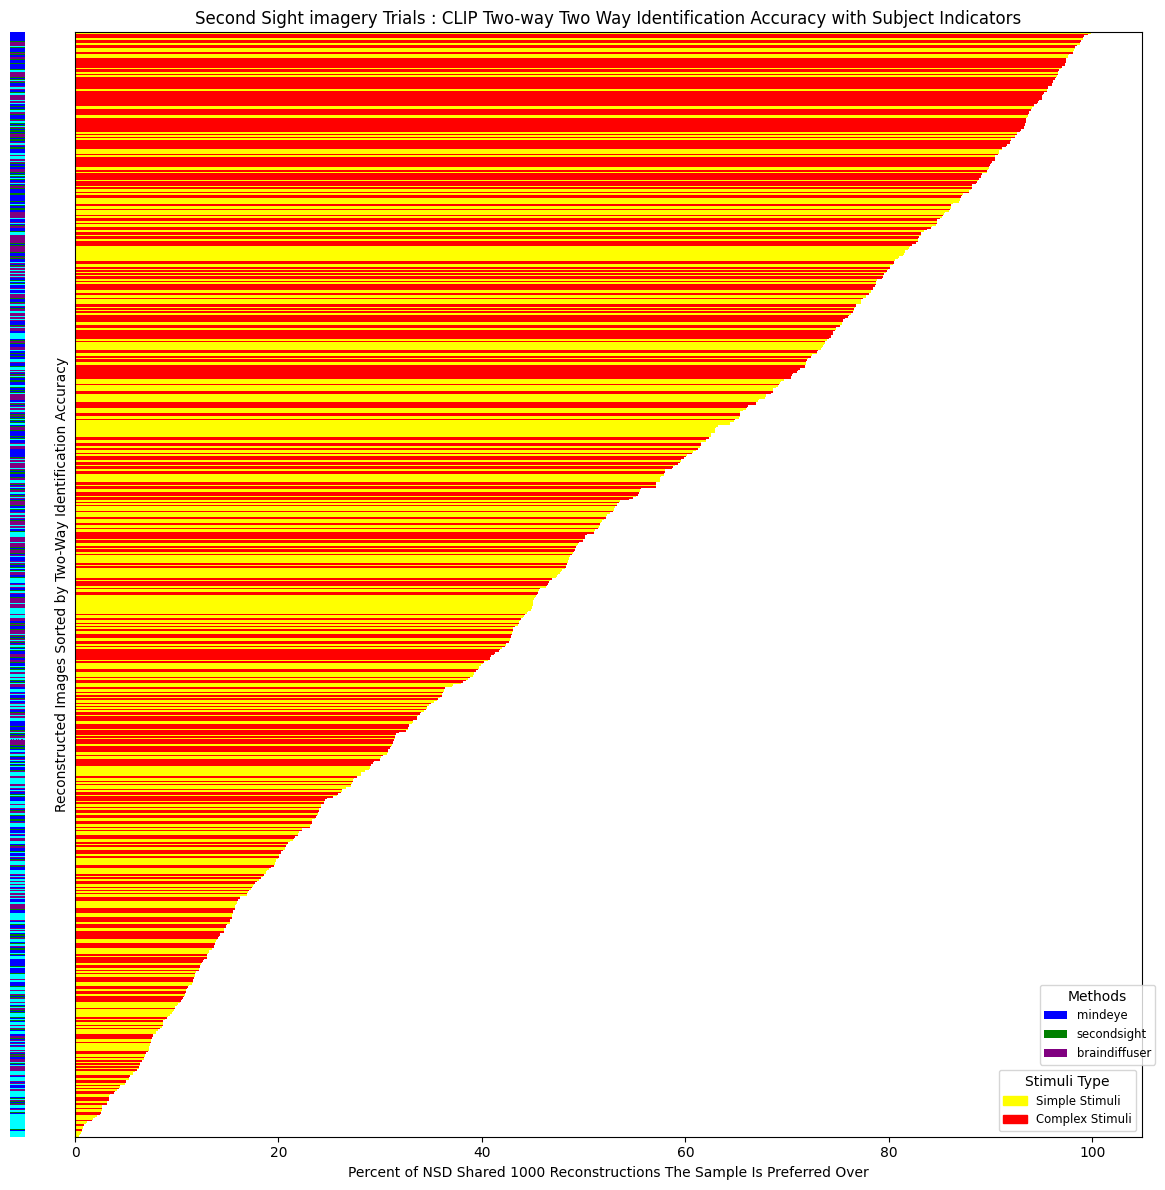

In [ ]:
# Update the sort order to ascending=True
# Filter and sort the dataframe
# mode = "vision"
mode = "imagery"
# feature = "Inception V3 1000"
# feature = "AlexNet 2 1000"
# feature = "AlexNet 5 1000"
# feature = "AlexNet 7 1000"
feature = "CLIP Two-way 1000"
feature_name = " ".join(feature.split()[:-1])

filtered_sorted_with_subject_df = df[(df['Sample Indicator'] == 12) & (df['Mode'] == mode)].dropna(subset=[feature])
filtered_sorted_with_subject_df = filtered_sorted_with_subject_df.sort_values(by=feature, ascending=False)

# Define unique subjects and their colors
unique_subjects = filtered_sorted_with_subject_df['Method'].unique()
subject_colors = ListedColormap(['blue', 'green', 'purple', 'cyan'])  # Bright color map
subject_color_map = {subject: idx for idx, subject in enumerate(unique_subjects)}

# Create the subject indicator matrix
subject_indicator_matrix = np.array([subject_color_map[subj] for subj in filtered_sorted_with_subject_df['Method']])

# Create the main figure and axes
fig, ax = plt.subplots(figsize=(13, 12))

# Plot the horizontal bars with no gaps in between by setting the height of each bar to 1
bar_colors = ['yellow' if ID <= 5 else 'red' for ID in filtered_sorted_with_subject_df['ID']]
ax.barh(
    y=range(len(filtered_sorted_with_subject_df)), 
    width=filtered_sorted_with_subject_df[feature] * 100,  # Scale the width to match the matrix plot scale
    height=1,  # Set the bar height to 1 to have the bars touch each other
    color=bar_colors,
    edgecolor='none'
)

# Reduce the margins to minimize empty space
ax.margins(y=0)  # Reduce margin to 0 on the y-axis

# Create a separate axis for the subject indicator, moving it further away from the main plot
divider = make_axes_locatable(ax)
ax_subject = divider.append_axes("left", size=0.15, pad=0.5, sharey=ax)  # Increase pad to move it away from the main plot

# Plot the subject indicator
ax_subject.imshow(subject_indicator_matrix[:, None], cmap=subject_colors, aspect='auto')

# Hide the spines, ticks, and labels for the subject indicator axis
ax_subject.set_xticks([])
ax_subject.set_yticks([])
ax_subject.set_yticklabels([])
for spine in ax_subject.spines.values():
    spine.set_visible(False)

# Set the labels and title for the main axis
ax.set_xlabel("Percent of NSD Shared 1000 Reconstructions The Sample Is Preferred Over")
ax.set_ylabel("Reconstructed Images Sorted by Two-Way Identification Accuracy")
ax.set_title(f"Second Sight {mode} Trials : {feature_name} Two Way Identification Accuracy with Subject Indicators")

# Create the legends
legend_elements_main = [
    mpatches.Patch(color='yellow', label='Simple Stimuli'),
    mpatches.Patch(color='red', label='Complex Stimuli')
]
ax.legend(handles=legend_elements_main, loc='lower right', fontsize='small', title="Stimuli Type")

# Reposition the Subjects legend to the bottom of the figure
legend_elements_subject = [mpatches.Patch(facecolor=subject_colors(i), label=f'{subj}') for i, subj in enumerate(unique_subjects)]
subject_legend = ax_subject.legend(handles=legend_elements_subject, loc='lower center', bbox_to_anchor=(72.5, 0.06), fontsize='small', title="Methods")

# Display the plot with a tight layout
plt.tight_layout()
plt.show()

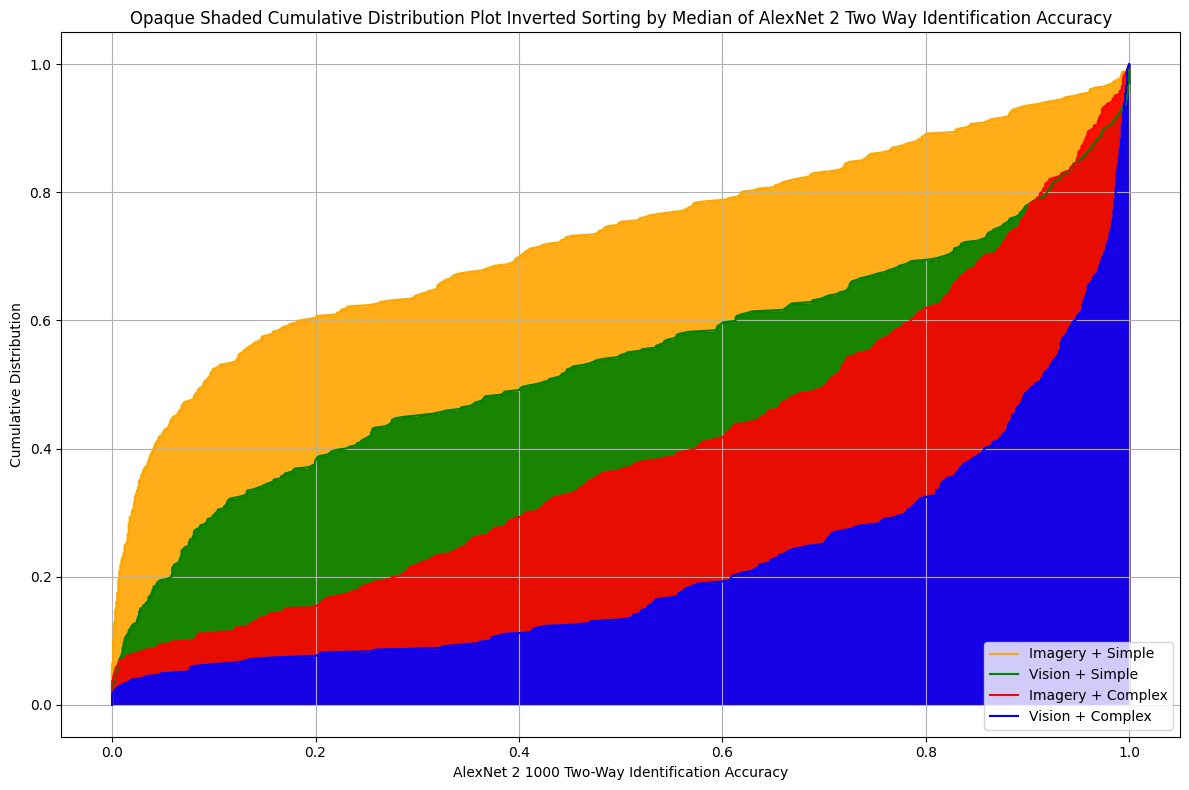

In [ ]:
# Define the feature of interest
# feature = "Inception V3 1000"
feature = "AlexNet 2 1000"
# feature = "AlexNet 5 1000"
# feature = "AlexNet 7 1000"
# feature = "CLIP Two-way 1000"

feature_name = " ".join(feature.split()[:-1])

# Function to plot with fill and increased opacity
def plot_with_fill_opaque(x, y, label, color):
    plt.fill_between(x, 0, y, step='post', alpha=0.9, color=color)  # Increased opacity
    plt.plot(x, y, label=label, color=color)

# Function to calculate cumulative distribution
def cumulative_distribution(data):
    # Sort data
    data_sorted = np.sort(data)
    # Calculate cumulative probability for each value in the sorted array
    p = 1. * np.arange(len(data)) / (len(data) - 1)
    return data_sorted, p

# Define the feature of interest and drop NaN values for the feature of interest
df_clean = df.dropna(subset=[feature])

# Separate the data into four groups
vision_complex = df_clean[(df_clean['Mode'] == 'vision') & (df_clean['ID'] > 5)][feature]
vision_simple = df_clean[(df_clean['Mode'] == 'vision') & (df_clean['ID'] <= 5)][feature]
imagery_complex = df_clean[(df_clean['Mode'] == 'imagery') & (df_clean['ID'] > 5)][feature]
imagery_simple = df_clean[(df_clean['Mode'] == 'imagery') & (df_clean['ID'] <= 5)][feature]

# Calculate cumulative distributions for each group
vision_complex_sorted, p_vision_complex = cumulative_distribution(vision_complex)
vision_simple_sorted, p_vision_simple = cumulative_distribution(vision_simple)
imagery_complex_sorted, p_imagery_complex = cumulative_distribution(imagery_complex)
imagery_simple_sorted, p_imagery_simple = cumulative_distribution(imagery_simple)

# Inverting the sorting order of the cumulative distributions by their median values for plotting
sorted_distributions_median_inverted = sorted([(vision_complex_sorted, p_vision_complex, 'Vision + Complex', 'blue'),
                                               (vision_simple_sorted, p_vision_simple, 'Vision + Simple', 'green'),
                                               (imagery_complex_sorted, p_imagery_complex, 'Imagery + Complex', 'red'),
                                               (imagery_simple_sorted, p_imagery_simple, 'Imagery + Simple', 'orange')],
                                              key=lambda x: np.median(x[0]), reverse=False)

# Plotting with filled areas and increased opacity
plt.figure(figsize=(12, 8))
for dist in sorted_distributions_median_inverted:
    plot_with_fill_opaque(dist[0], dist[1], dist[2], dist[3])

# Adding labels and title
feature_name = " ".join(feature.split()[:-1])
plt.xlabel(f'{feature} Two-Way Identification Accuracy')
plt.ylabel('Cumulative Distribution')
plt.title(f'Opaque Shaded Cumulative Distribution Plot Inverted Sorting by Median of {feature_name} Two Way Identification Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig(f"output/mental_imagery_paper/figures/density_{feature_name}_no_tagaki.png")
plt.show()


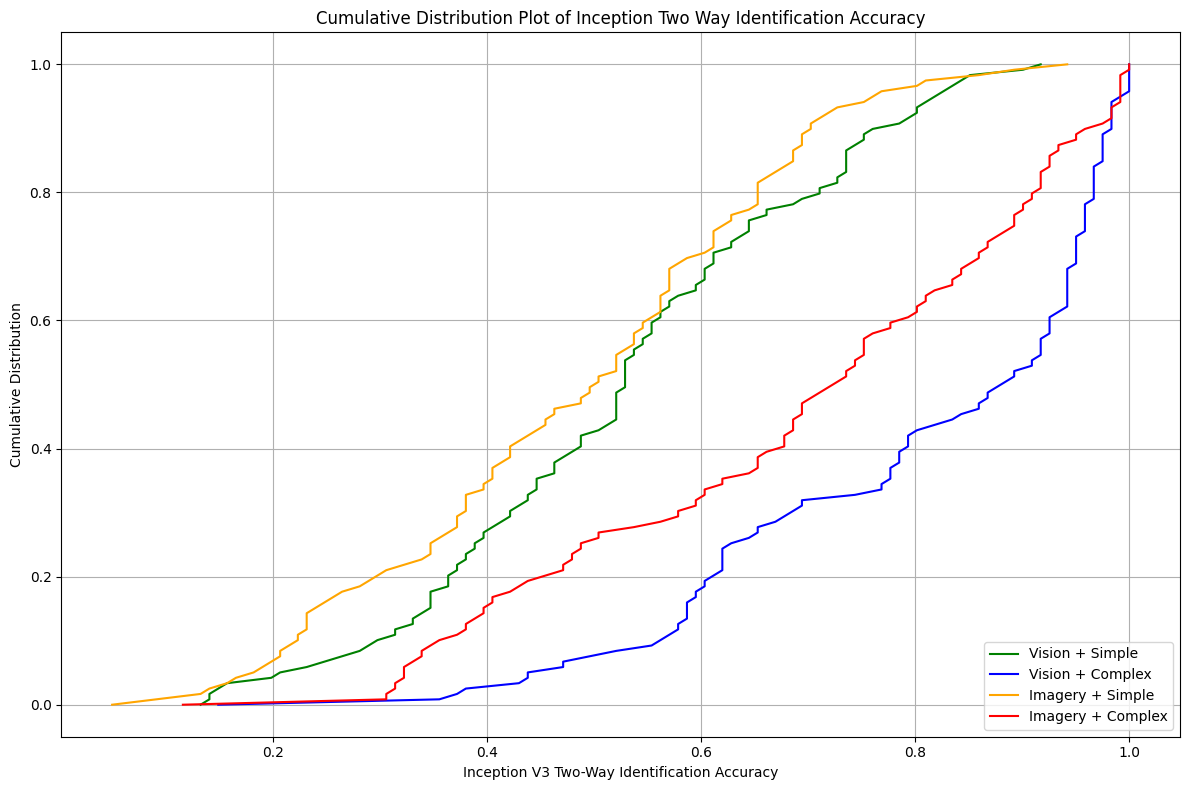

In [ ]:
# Drop NaN values for the feature of interest
df_clean = df.dropna(subset=[feature])
# Group the data by method, subject, and sample, and calculate the average of the feature column
grouped_df = df_clean.groupby(['Method', 'Subject', 'ID', 'Mode'])[feature].mean().reset_index()
# Separate the data into four groups
vision_complex = grouped_df[(grouped_df['Mode'] == 'vision') & (grouped_df['ID'] > 5)][feature]
vision_simple = grouped_df[(grouped_df['Mode'] == 'vision') & (grouped_df['ID'] <= 5)][feature]
imagery_complex = grouped_df[(grouped_df['Mode'] == 'imagery') & (grouped_df['ID'] > 5)][feature]
imagery_simple = grouped_df[(grouped_df['Mode'] == 'imagery') & (grouped_df['ID'] <= 5)][feature]

# Function to calculate cumulative distribution
def cumulative_distribution(data):
    # Sort data
    data_sorted = np.sort(data)
    # Calculate cumulative probability for each value in the sorted array
    p = 1. * np.arange(len(data)) / (len(data) - 1)
    return data_sorted, p

# Calculate cumulative distributions for each group
vision_complex_sorted, p_vision_complex = cumulative_distribution(vision_complex)
vision_simple_sorted, p_vision_simple = cumulative_distribution(vision_simple)
imagery_complex_sorted, p_imagery_complex = cumulative_distribution(imagery_complex)
imagery_simple_sorted, p_imagery_simple = cumulative_distribution(imagery_simple)

# Plotting
plt.figure(figsize=(12, 8))
plt.plot(vision_simple_sorted, p_vision_simple, color='green', label='Vision + Simple')
plt.plot(vision_complex_sorted, p_vision_complex, color='blue', label='Vision + Complex')
plt.plot(imagery_simple_sorted, p_imagery_simple, color='orange', label='Imagery + Simple')
plt.plot(imagery_complex_sorted, p_imagery_complex, color='red', label='Imagery + Complex')

# Adding labels and title
plt.xlabel(f'{feature} Two-Way Identification Accuracy')
plt.ylabel('Cumulative Distribution')
plt.title(f'Cumulative Distribution Plot of {feature_name} Two Way Identification Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()


     Unnamed: 0  ID  Subject    Method     Mode  Sample Count  Batch Number  \
1             1   0        1   mindeye   vision           NaN           NaN   
2             2   0        1   mindeye   vision           0.0           NaN   
3             3   0        1   mindeye   vision           1.0           NaN   
4             4   0        1   mindeye   vision           2.0           NaN   
5             5   0        1   mindeye   vision           3.0           NaN   
..          ...  ..      ...       ...      ...           ...           ...   
139         139  11        7  mindeye2  imagery           5.0           NaN   
140         140  11        7  mindeye2  imagery           6.0           NaN   
141         141  11        7  mindeye2  imagery           7.0           NaN   
142         142  11        7  mindeye2  imagery           8.0           NaN   
143         143  11        7  mindeye2  imagery           9.0           NaN   

     Sample Indicator  Strength  Brain Correlation 

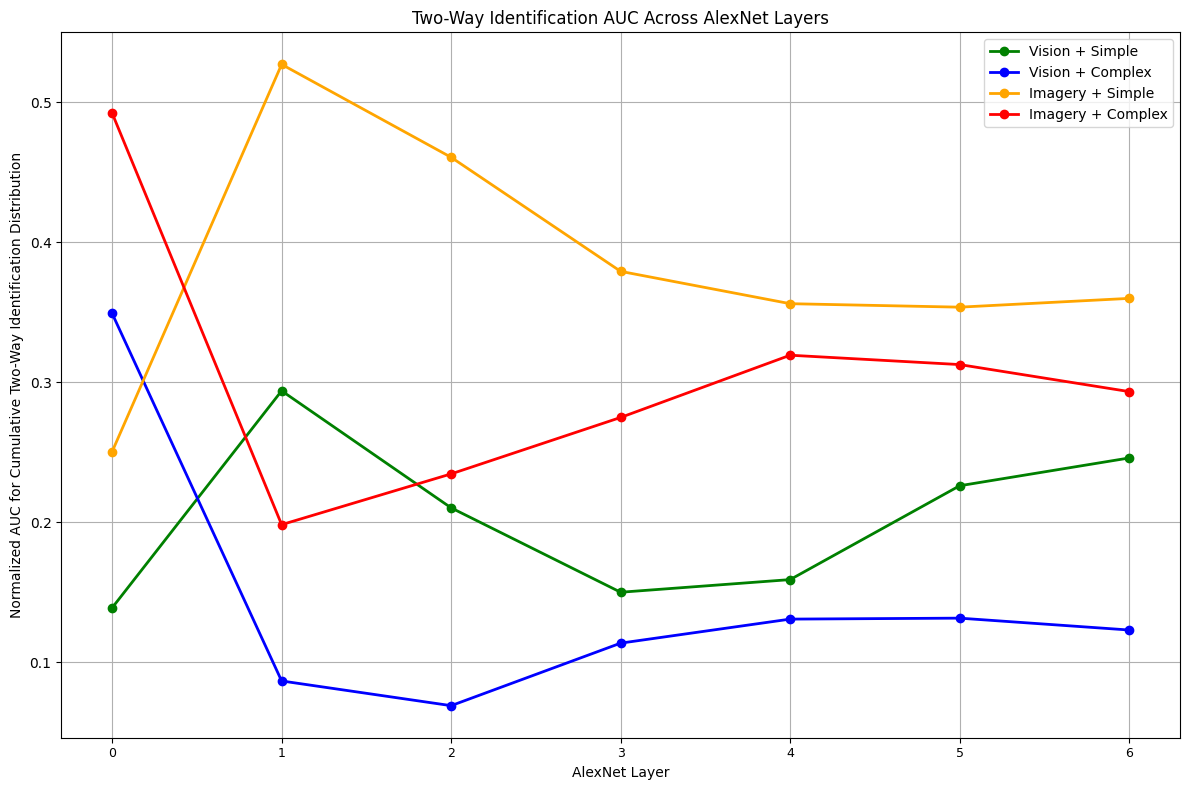

In [ ]:
feature_dict = {}
feature_dict = {"vision_complex": [], "vision_simple": [], "imagery_complex": [], "imagery_simple": []}
net_list = [
            'AlexNet 1',
            'AlexNet 2',
            'AlexNet 3',
            'AlexNet 4',
            'AlexNet 5',
            'AlexNet 6',
            'AlexNet 7']
for feature in net_list:
    df_clean = df.dropna(subset=[f'{feature}'])
    print(df_clean)
    # Separate the data into four groups
    vision_complex = df_clean[(df_clean['Mode'] == 'vision') & (df_clean['ID'] > 5)][f'{feature}']
    vision_simple = df_clean[(df_clean['Mode'] == 'vision') & (df_clean['ID'] <= 5)][f'{feature}']
    imagery_complex = df_clean[(df_clean['Mode'] == 'imagery') & (df_clean['ID'] > 5)][f'{feature}']
    imagery_simple = df_clean[(df_clean['Mode'] == 'imagery') & (df_clean['ID'] <= 5)][f'{feature}']

    # Calculate cumulative distributions for each group
    vision_complex_sorted, p_vision_complex = cumulative_distribution(vision_complex)
    vision_simple_sorted, p_vision_simple = cumulative_distribution(vision_simple)
    imagery_complex_sorted, p_imagery_complex = cumulative_distribution(imagery_complex)
    imagery_simple_sorted, p_imagery_simple = cumulative_distribution(imagery_simple)

    # Normalize the sorted data to 1
    vision_complex_sorted_normalized = vision_complex_sorted / vision_complex_sorted.max()
    vision_simple_sorted_normalized = vision_simple_sorted / vision_simple_sorted.max()
    imagery_complex_sorted_normalized = imagery_complex_sorted / imagery_complex_sorted.max()
    imagery_simple_sorted_normalized = imagery_simple_sorted / imagery_simple_sorted.max()

    # Calculate the area under each normalized curve using the trapezoidal rule
    area_vision_complex = np.trapz(p_vision_complex, vision_complex_sorted)
    area_vision_simple = np.trapz(p_vision_simple, vision_simple_sorted)
    area_imagery_complex = np.trapz(p_imagery_complex, imagery_complex_sorted)
    area_imagery_simple = np.trapz(p_imagery_simple, imagery_simple_sorted)
    feature_dict["vision_complex"].append(area_vision_complex)
    feature_dict["vision_simple"].append(area_vision_simple)
    feature_dict["imagery_complex"].append(area_imagery_complex)
    feature_dict["imagery_simple"].append(area_imagery_simple)
    
plt.figure(figsize=(12, 8))
plt.plot(feature_dict["vision_simple"], color='green', label='Vision + Simple', marker='o', linewidth=2)
plt.plot(feature_dict["vision_complex"], color='blue', label='Vision + Complex', marker='o', linewidth=2)
plt.plot(feature_dict["imagery_simple"], color='orange', label='Imagery + Simple', marker='o', linewidth=2)
plt.plot(feature_dict["imagery_complex"], color='red', label='Imagery + Complex', marker='o', linewidth=2)

# Adding labels and title
plt.xlabel("AlexNet Layer")
plt.ylabel('Normalized AUC for Cumulative Two-Way Identification Distribution')
plt.title(f'Two-Way Identification AUC Across AlexNet Layers')
plt.legend(loc='upper right')
plt.xticks(range(7), fontsize=9)
plt.grid(True)
plt.tight_layout()

100%|██████████| 1000/1000 [00:06<00:00, 142.95it/s]


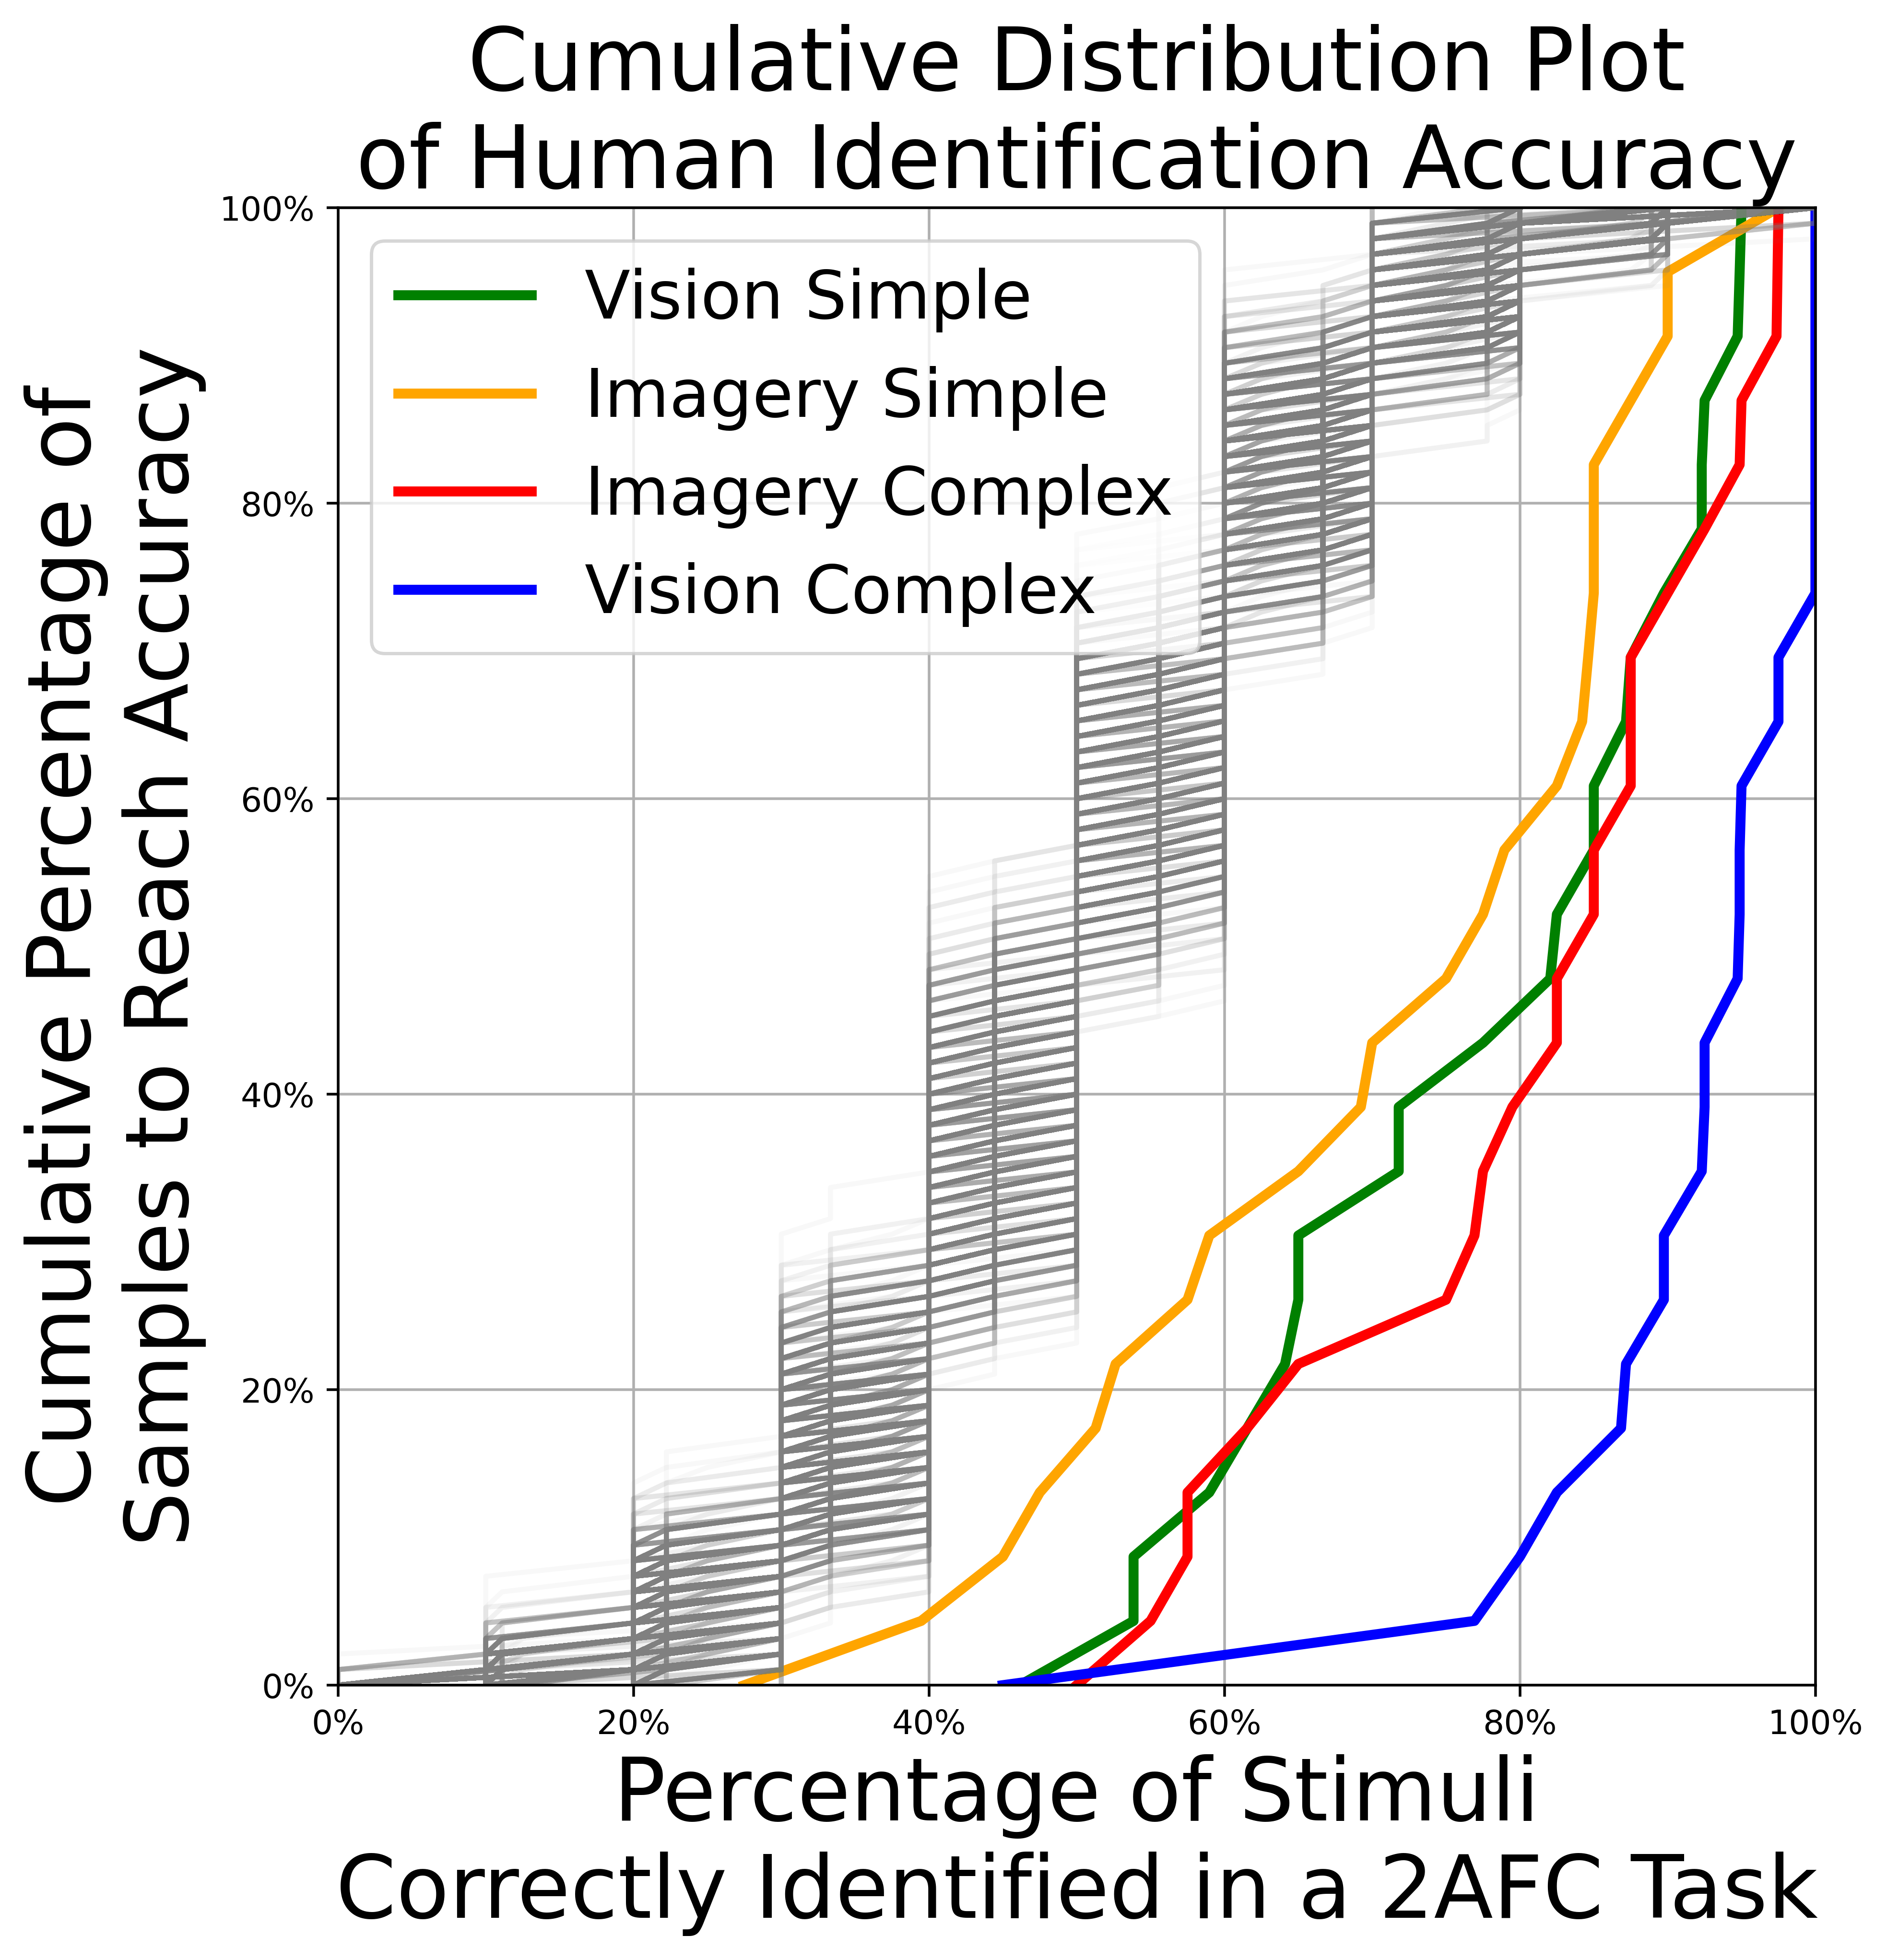

In [16]:


human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
human_df = human_df[(human_df['experiment'] == 1) & (human_df['method'] != "tagaki") & (human_df['method'] != "mindeye2")]
grouped_data = human_df.groupby(['sample', 'subject', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
grouped_data.rename(columns={'picked_target': 'Accuracy'}, inplace=True)
grouped_data['Accuracy'] *= 100

# Function to calculate cumulative distribution
def cumulative_distribution(data):
    # Sort data
    data_sorted = np.sort(data)
    # Calculate cumulative probability for each value in the sorted array
    p = 100. * np.arange(len(data)) / (len(data) - 1)
    return data_sorted, p

# Separate the data into the four groups
vision_complex = grouped_data[(grouped_data['mode'] == 'vision') & (grouped_data['stimtype'] == 'complex')]['Accuracy']
vision_simple = grouped_data[(grouped_data['mode'] == 'vision') & (grouped_data['stimtype'] == 'simple')]['Accuracy']
imagery_complex = grouped_data[(grouped_data['mode'] == 'imagery') & (grouped_data['stimtype'] == 'complex')]['Accuracy']
imagery_simple = grouped_data[(grouped_data['mode'] == 'imagery') & (grouped_data['stimtype'] == 'simple')]['Accuracy']

# Calculate cumulative distributions for each group using the previously defined function
vision_complex_sorted, p_vision_complex = cumulative_distribution(vision_complex)
vision_simple_sorted, p_vision_simple = cumulative_distribution(vision_simple)
imagery_complex_sorted, p_imagery_complex = cumulative_distribution(imagery_complex)
imagery_simple_sorted, p_imagery_simple = cumulative_distribution(imagery_simple)

# Plotting
fig, ax = plt.subplots(figsize=(8, 8), dpi=500)  # Create a square figure
ax.plot(vision_simple_sorted, p_vision_simple, color='green', label='Vision Simple', linewidth=3)
ax.plot(imagery_simple_sorted, p_imagery_simple, color='orange', label='Imagery Simple', linewidth=3)
ax.plot(imagery_complex_sorted, p_imagery_complex, color='red', label='Imagery Complex', linewidth=3)
ax.plot(vision_complex_sorted, p_vision_complex, color='blue', label='Vision Complex', linewidth=3)

for _ in tqdm(range(1000)):
    # Randomize 'picked_target'
    randomized_df = human_df.copy()
    randomized_df['picked_target'] = np.random.rand(len(randomized_df)) < 0.5

    # Group and calculate new accuracies
    randomized_grouped_data = randomized_df.groupby(['sample', 'subject', 'method', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
    randomized_grouped_data.rename(columns={'picked_target': 'Accuracy'}, inplace=True)
    randomized_grouped_data['Accuracy'] *= 100
    # Separate the data into the four groups
    randomized_vision_complex = randomized_grouped_data[(randomized_grouped_data['mode'] == 'vision') & (randomized_grouped_data['stimtype'] == 'complex')]['Accuracy']
    randomized_vision_simple = randomized_grouped_data[(randomized_grouped_data['mode'] == 'vision') & (randomized_grouped_data['stimtype'] == 'simple')]['Accuracy']
    randomized_imagery_complex = randomized_grouped_data[(randomized_grouped_data['mode'] == 'imagery') & (randomized_grouped_data['stimtype'] == 'complex')]['Accuracy']
    randomized_imagery_simple = randomized_grouped_data[(randomized_grouped_data['mode'] == 'imagery') & (randomized_grouped_data['stimtype'] == 'simple')]['Accuracy']

    # Calculate cumulative distributions for each randomized group
    r_vision_complex_sorted, r_p_vision_complex = cumulative_distribution(randomized_vision_complex)
    r_vision_simple_sorted, r_p_vision_simple = cumulative_distribution(randomized_vision_simple)
    r_imagery_complex_sorted, r_p_imagery_complex = cumulative_distribution(randomized_imagery_complex)
    r_imagery_simple_sorted, r_p_imagery_simple = cumulative_distribution(randomized_imagery_simple)

    # Plot the randomized data
    ax.plot(r_vision_simple_sorted, r_p_vision_simple, color="gray", alpha=0.05)
    ax.plot(r_vision_complex_sorted, r_p_vision_complex, color="gray", alpha=0.05)
    ax.plot(r_imagery_simple_sorted, r_p_imagery_simple, color="gray", alpha=0.05)
    ax.plot(r_imagery_complex_sorted, r_p_imagery_complex, color="gray", alpha=0.05)

# Adding labels and title
ax.set_xlabel(f'Percentage of Stimuli\nCorrectly Identified in a 2AFC Task', fontsize=26)
ax.set_ylabel('Cumulative Percentage of\nSamples to Reach Accuracy', fontsize=26)
ax.set_title(f'Cumulative Distribution Plot\nof Human Identification Accuracy', fontsize=26)
ax.legend(loc='upper left', fontsize=20)
ax.grid(True)
# plt.tight_layout()
# Format x-axis ticks as percentages
ax.xaxis.set_major_formatter(mtick.PercentFormatter())

# Format y-axis ticks as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
# Set the x-axis limit to end at 100%
ax.set_xlim(0, 100)

# Set the y-axis limit to end at 100%
ax.set_ylim(0, 100)

# Ensure the aspect ratio of the plot is equal
ax.set_aspect('equal', adjustable='box')

plt.show()


100%|██████████| 100/100 [00:02<00:00, 47.41it/s]


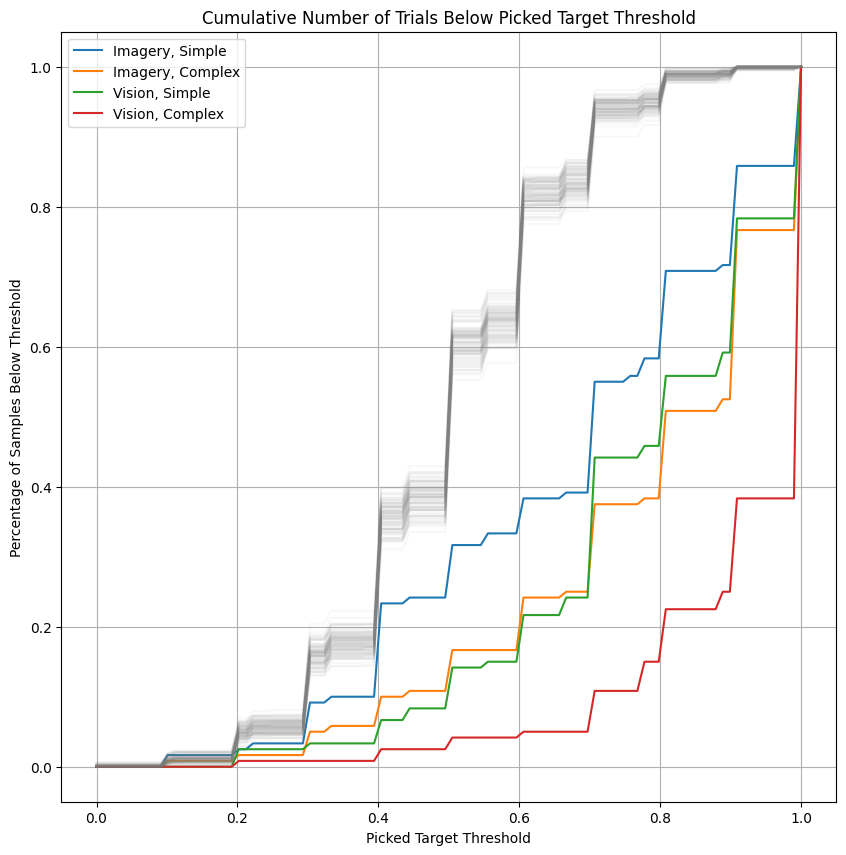

In [ ]:
human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['method'] != 'tagaki') & (human_df['experiment'] == 1)]
grouped_data = human_df.groupby(['sample', 'subject', 'method', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
thresholds = np.linspace(0, 1, 100)
cumulative_counts_below = {('imagery', 'simple'): [],
                     ('imagery', 'complex'): [],
                     ('vision', 'simple'): [],
                     ('vision', 'complex'): []}
cumulative_counts_random = np.zeros((100,100))
for threshold in thresholds:
    for mode, stimtype in cumulative_counts_below.keys():
        count_below_threshold = grouped_data[(grouped_data['mode'] == mode) & 
                                             (grouped_data['stimtype'] == stimtype) & 
                                             (grouped_data['picked_target'] <= threshold)].shape[0]
        total_count = grouped_data[(grouped_data['mode'] == mode) & 
                                   (grouped_data['stimtype'] == stimtype)].shape[0]
        percentage_below_threshold = (count_below_threshold / total_count) if total_count else 0
        cumulative_counts_below[(mode, stimtype)].append(percentage_below_threshold)
for j in tqdm(range(100)):
    randomized_df = human_df.copy()
    # Randomize 'picked_target'
    randomized_df['picked_target'] = np.random.rand(len(randomized_df)) < 0.5
    randomized_grouped_data = randomized_df.groupby(['sample', 'subject', 'method', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
    for i, threshold in enumerate(thresholds):
        count_below_threshold_random = randomized_grouped_data[(randomized_grouped_data['picked_target'] <= threshold)].shape[0]
        total_count_random = randomized_grouped_data.shape[0]
        percentage_below_threshold_random = (count_below_threshold_random / total_count_random) if total_count_random else 0
        cumulative_counts_random[i, j] = percentage_below_threshold_random
# Plotting the line plots for below threshold counts
plt.figure(figsize=(10, 10))

for (mode, stimtype), percentages in cumulative_counts_below.items():
    plt.plot(thresholds, percentages, label=f"{mode.capitalize()}, {stimtype.capitalize()}")
cumulative_counts_random = cumulative_counts_random.T
for i, random_percentages in enumerate(cumulative_counts_random):
    plt.plot(thresholds, random_percentages, color="gray", alpha=0.05)

plt.xlabel('Picked Target Threshold')
plt.ylabel('Percentage of Samples Below Threshold')
plt.title('Cumulative Number of Trials Below Picked Target Threshold')
plt.legend()
plt.grid(True)
plt.show()

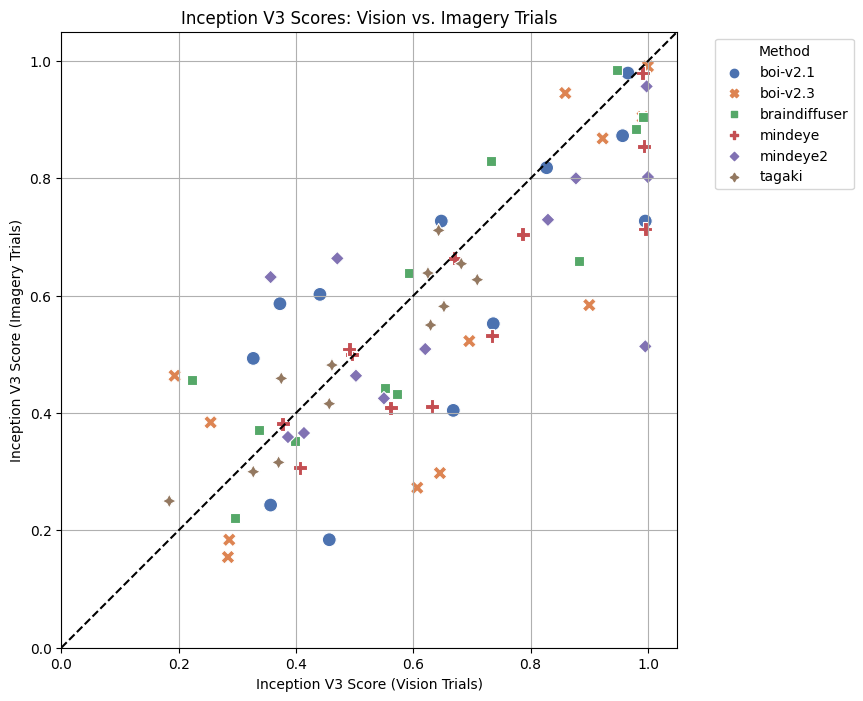

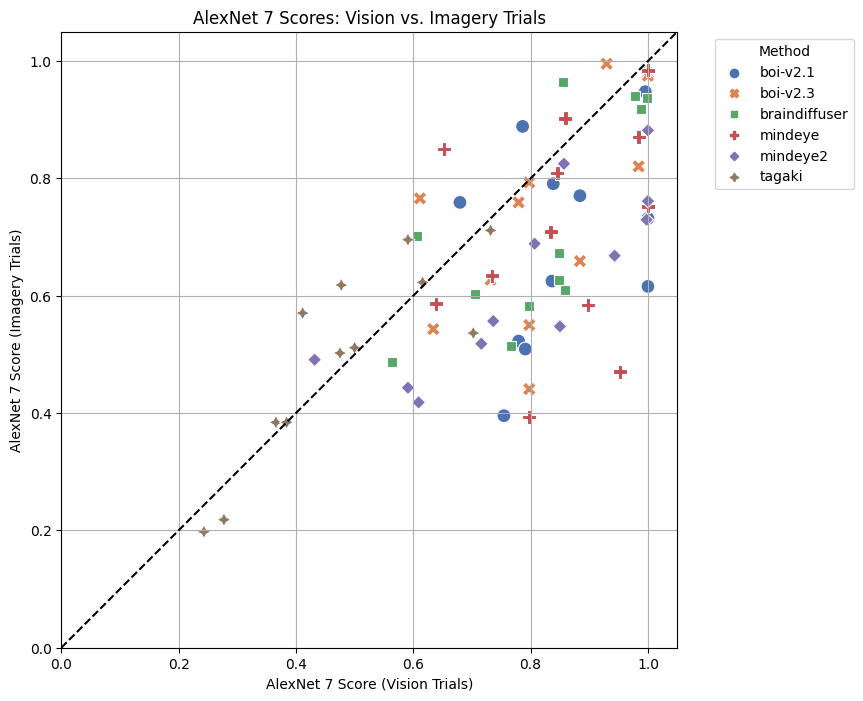

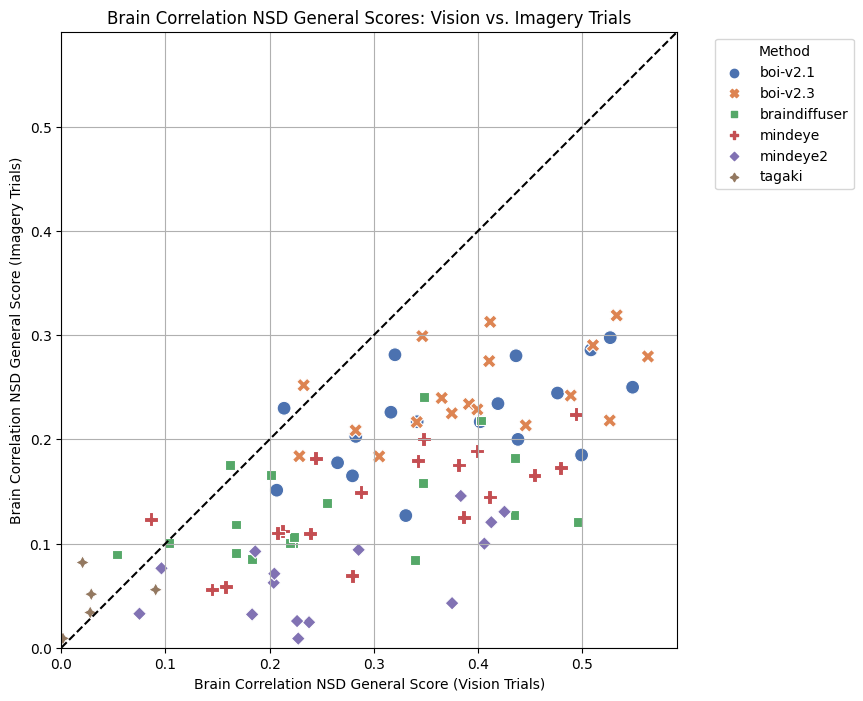

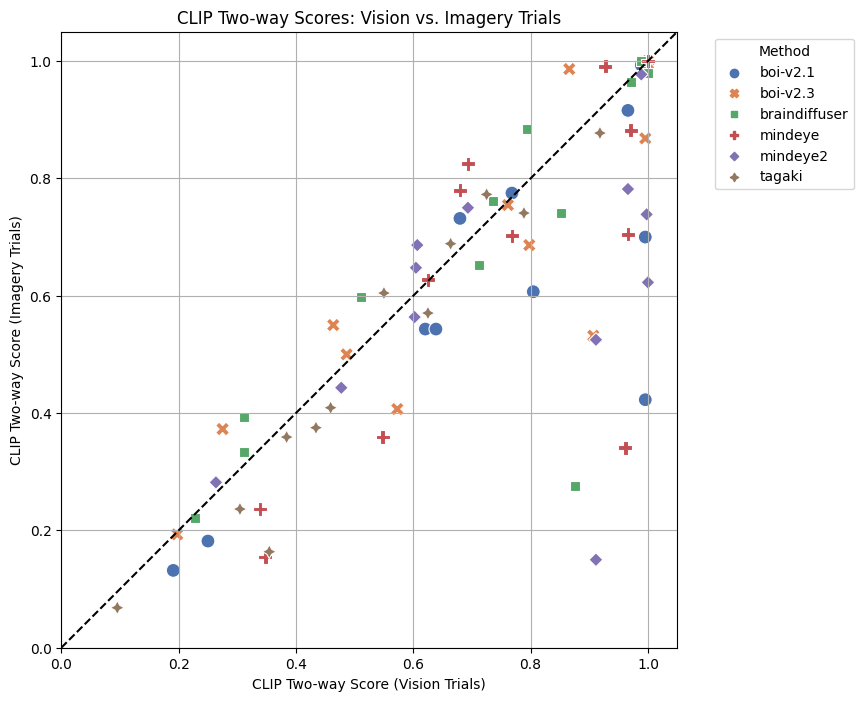

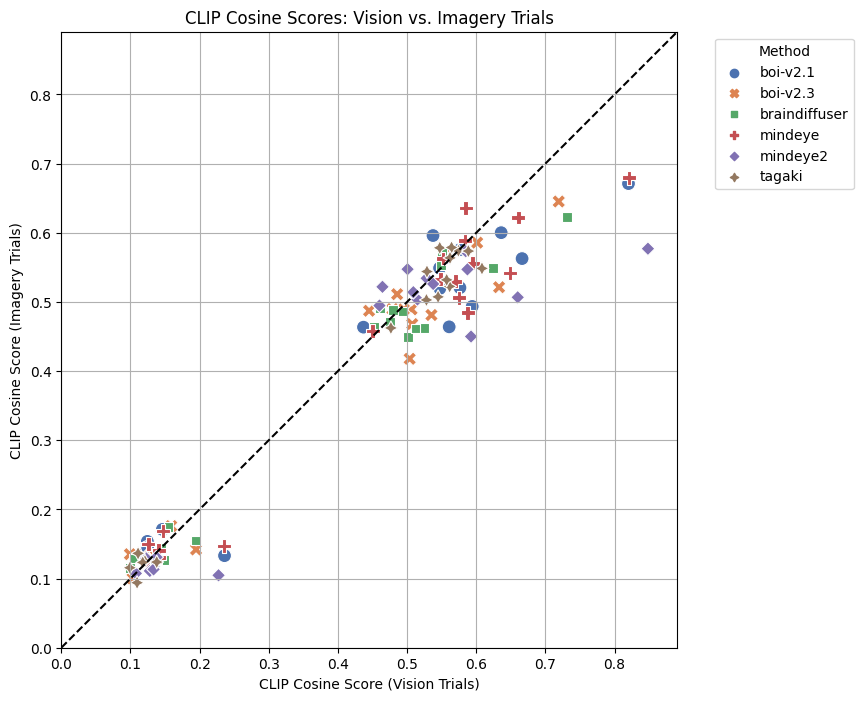

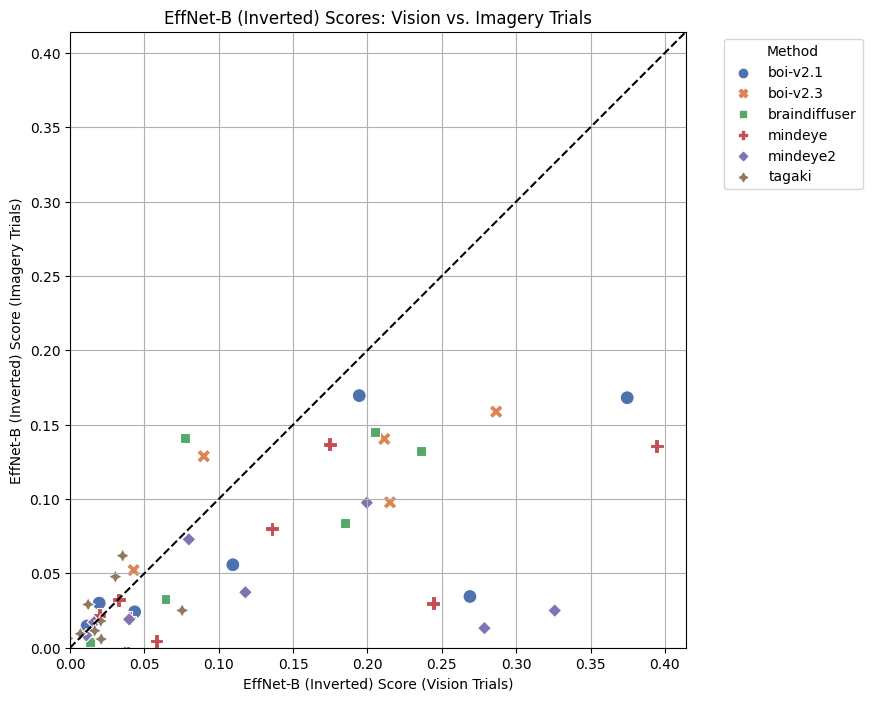

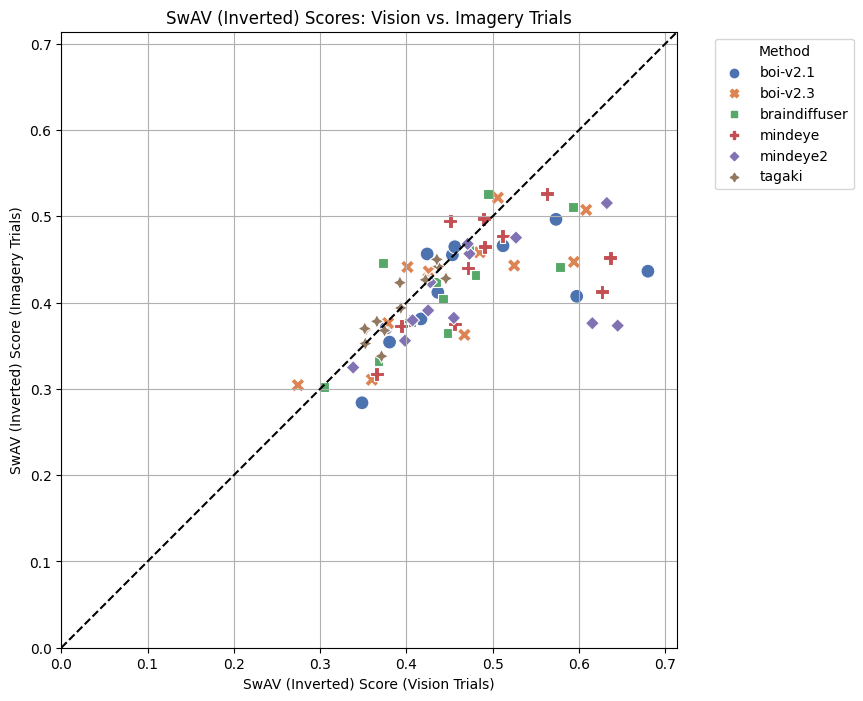

In [ ]:
# Preprocessing steps
# Group the DataFrame by 'Method', 'Mode', 'ID', and 'Sample Indicator' and calculate the mean for each group
# grouped_df = df.groupby(['Method', 'Mode', 'ID', 'Sample Indicator'])
# print(grouped_df)
# grouped_df = grouped_df.mean().reset_index()
# print(grouped_df)
filtered_df = df[df['Sample Indicator'] == 12]

grouped_df = filtered_df.groupby(['Method', 'Mode', 'ID', 'Sample Indicator']).mean().reset_index()

# Separate DataFrames for Vision and Imagery trials based on Mode
vision_df = grouped_df[grouped_df['Mode'] == 'vision']
imagery_df = grouped_df[grouped_df['Mode'] == 'imagery']

# Define the feature column you wish to plot
feature_column = 'Inception V3'  # Change this to the column name of the feature you wish to plot
for feature_column in ["Inception V3", "AlexNet 7", "Brain Correlation NSD General", "CLIP Two-way", "CLIP Cosine", "EffNet-B", "SwAV"]:
    # Merging the vision and imagery DataFrames on 'ID' and 'Method' to align them for comparison
    merged_df = pd.merge(
        vision_df[['ID', 'Method', feature_column]],
        imagery_df[['ID', 'Method', feature_column]],
        on=['ID', 'Method'],
        suffixes=('_Vision', '_Imagery')
    )
    
    # Invert feature values for EffNet-B and SwAV
    if feature_column in ["EffNet-B", "SwAV"]:
        merged_df[f'{feature_column}_Vision'] = 1 - merged_df[f'{feature_column}_Vision']
        merged_df[f'{feature_column}_Imagery'] = 1 - merged_df[f'{feature_column}_Imagery']
    # Finding the maximum value for scaling
    max_value = max(merged_df[f'{feature_column}_Vision'].max(), merged_df[f'{feature_column}_Imagery'].max())
    max_value_padded = max_value + 0.05 * max_value  # Padding the max value by 5%

    # Plotting
    plt.figure(figsize=(8, 8))
    sns.scatterplot(data=merged_df, x=f'{feature_column}_Vision', y=f'{feature_column}_Imagery', hue='Method', style='Method', palette='deep', s=100)
    if feature_column in ["EffNet-B", "SwAV"]:
        feature_column += " (Inverted)"
    plt.title(f'{feature_column} Scores: Vision vs. Imagery Trials')
    plt.xlabel(f'{feature_column} Score (Vision Trials)')
    plt.ylabel(f'{feature_column} Score (Imagery Trials)')
    plt.legend(title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.xlim(0, max_value_padded)  # Setting x and y axes limits to the padded maximum value
    plt.ylim(0, max_value_padded)
    plt.gca().set_aspect('equal', adjustable='box')  # Ensuring the plot remains square
    plt.plot([0, max_value_padded], [0, max_value_padded], 'k--')  # Adding a line at unity
    plt.show()

/tmp/ipykernel_51999/211884801.py:4: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()
/tmp/ipykernel_51999/211884801.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df_detailed = human_df.groupby(['method', 'sample', 'subject', 'rep']).mean().reset_index()


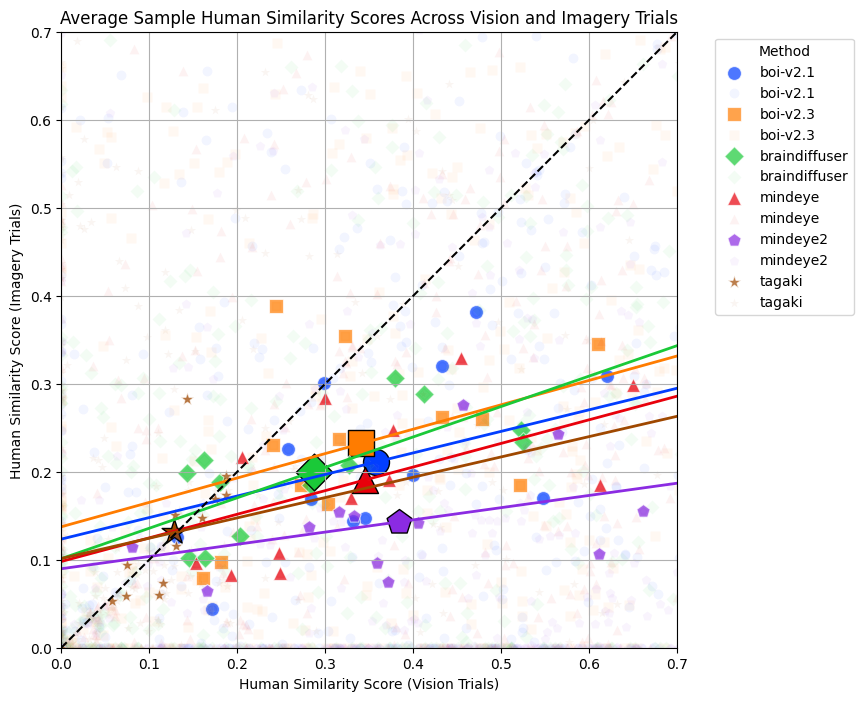

In [13]:

human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['experiment'] == 2)]
grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()
grouped_df_detailed = human_df.groupby(['method', 'sample', 'subject', 'rep']).mean().reset_index()
methods = grouped_df['method'].unique()
# methods = ["tagaki"]
plt.figure(figsize=(8, 8))

# Bright and distinct color palette
bright_palette = sns.color_palette('bright', len(methods))

# Scatter plot with distinct markers for each method
markers = ['o', 's', 'D', '^', 'p', '*']  # Different markers for each method

# Preparing to fit lines and plot them on top of the points
line_data = {}
for i, row in grouped_df.iterrows():
    method = row['method']
    color = bright_palette[methods.tolist().index(method)]
    marker = markers[methods.tolist().index(method)]
    plt.gca()
    plt.plot(row['target_similarity'], row['distractor_similarity'], marker=marker, color=color, linestyle='None', alpha=0.1)
    
for i, method in enumerate(methods):
    # Filter data for the current method
    method_data = grouped_df[grouped_df['method'] == method]
    method_data_detailed = grouped_df_detailed[grouped_df_detailed['method'] == method]
    # Fit line
    m, b = np.polyfit(method_data_detailed['target_similarity'], method_data_detailed['distractor_similarity'], 1)
    line_data[method] = (m, b)

    sns.scatterplot(data=method_data, x='target_similarity', y='distractor_similarity', color=bright_palette[i], 
                    label=method, s=100, marker=markers[i], alpha=0.7)
    
    sns.scatterplot(data=method_data_detailed, x='target_similarity', y='distractor_similarity', color=bright_palette[i], 
                    label=method, s=50, marker=markers[i], alpha=0.05)
    
    avg_target_similarity = method_data['target_similarity'].mean()
    avg_distractor_similarity = method_data['distractor_similarity'].mean()
    plt.scatter(avg_target_similarity, avg_distractor_similarity, color=bright_palette[i], marker=markers[i], s=350, edgecolors='black')

# Plotting lines on top of the points
for i, method in enumerate(methods):
    
    m, b = line_data[method]
    plt.plot([0, 0.7], [m*0 + b, m*0.7 + b], color=bright_palette[i], linewidth=2)


plt.title('Average Sample Human Similarity Scores Across Vision and Imagery Trials')
plt.xlabel('Human Similarity Score (Vision Trials)')
plt.ylabel('Human Similarity Score (Imagery Trials)')
plt.legend(title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.xlim(0, 0.7)
plt.ylim(0, 0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.plot([0, 0.7], [0, 0.7], 'k--')  # Adding a line at unity
plt.show()

/tmp/ipykernel_62666/1800609878.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = human_df.groupby(['method', 'mode', 'sample']).mean().reset_index()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


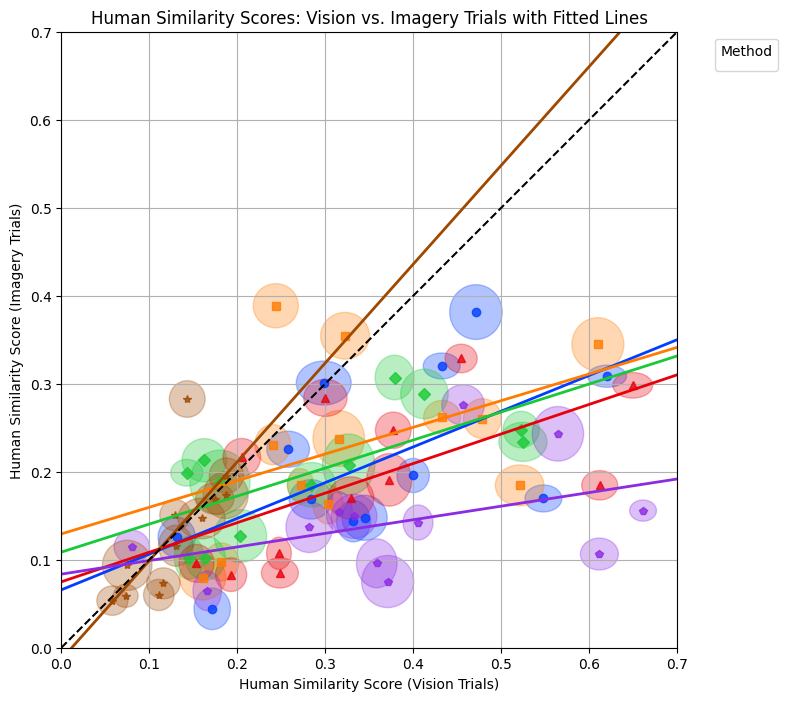

In [3]:
human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['experiment'] == 2)]

grouped_df = human_df.groupby(['method', 'mode', 'sample']).mean().reset_index()
grouped_df_detailed = human_df.groupby(['method', 'mode', 'sample', 'subject', 'rep']).mean().reset_index()
methods = grouped_df['method'].unique()
# methods = ["tagaki"]
plt.figure(figsize=(8, 8))

# Bright and distinct color palette
bright_palette = sns.color_palette('bright', len(methods))

# Scatter plot with distinct markers for each method
markers = ['o', 's', 'D', '^', 'p', '*']  # Different markers for each method

# Preparing to fit lines and plot them on top of the points
line_data = {}
for i, row in grouped_df.iterrows():
    method = row['method']
    color = bright_palette[methods.tolist().index(method)]
    marker = markers[methods.tolist().index(method)]
    e = Ellipse(xy=(row['target_similarity'], row['distractor_similarity']), 
                width=row['distractor_confidence'] * 0.2,  # Actual confidence value
                height=row['target_confidence'] * 0.2,  # Actual confidence value
                alpha=0.3, 
                color=color)
    plt.gca().add_artist(e)
    plt.plot(row['target_similarity'], row['distractor_similarity'], marker=marker, color=color, linestyle='None', alpha=0.8)

# Plotting lines on top of the points
for i, method in enumerate(methods):
    method_data = grouped_df[grouped_df['method'] == method]
    m, b = np.polyfit(method_data['target_similarity'], method_data['distractor_similarity'], 1)
    plt.plot([0, 0.7], [m*0 + b, m*0.7 + b], color=bright_palette[i], linewidth=2)

plt.title('Human Similarity Scores: Vision vs. Imagery Trials with Fitted Lines')
plt.xlabel('Human Similarity Score (Vision Trials)')
plt.ylabel('Human Similarity Score (Imagery Trials)')
plt.legend(title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.xlim(0, 0.7)
plt.ylim(0, 0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.plot([0, 0.7], [0, 0.7], 'k--')  # Adding a line at unity
plt.show()

/tmp/ipykernel_125473/1712507705.py:11: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()


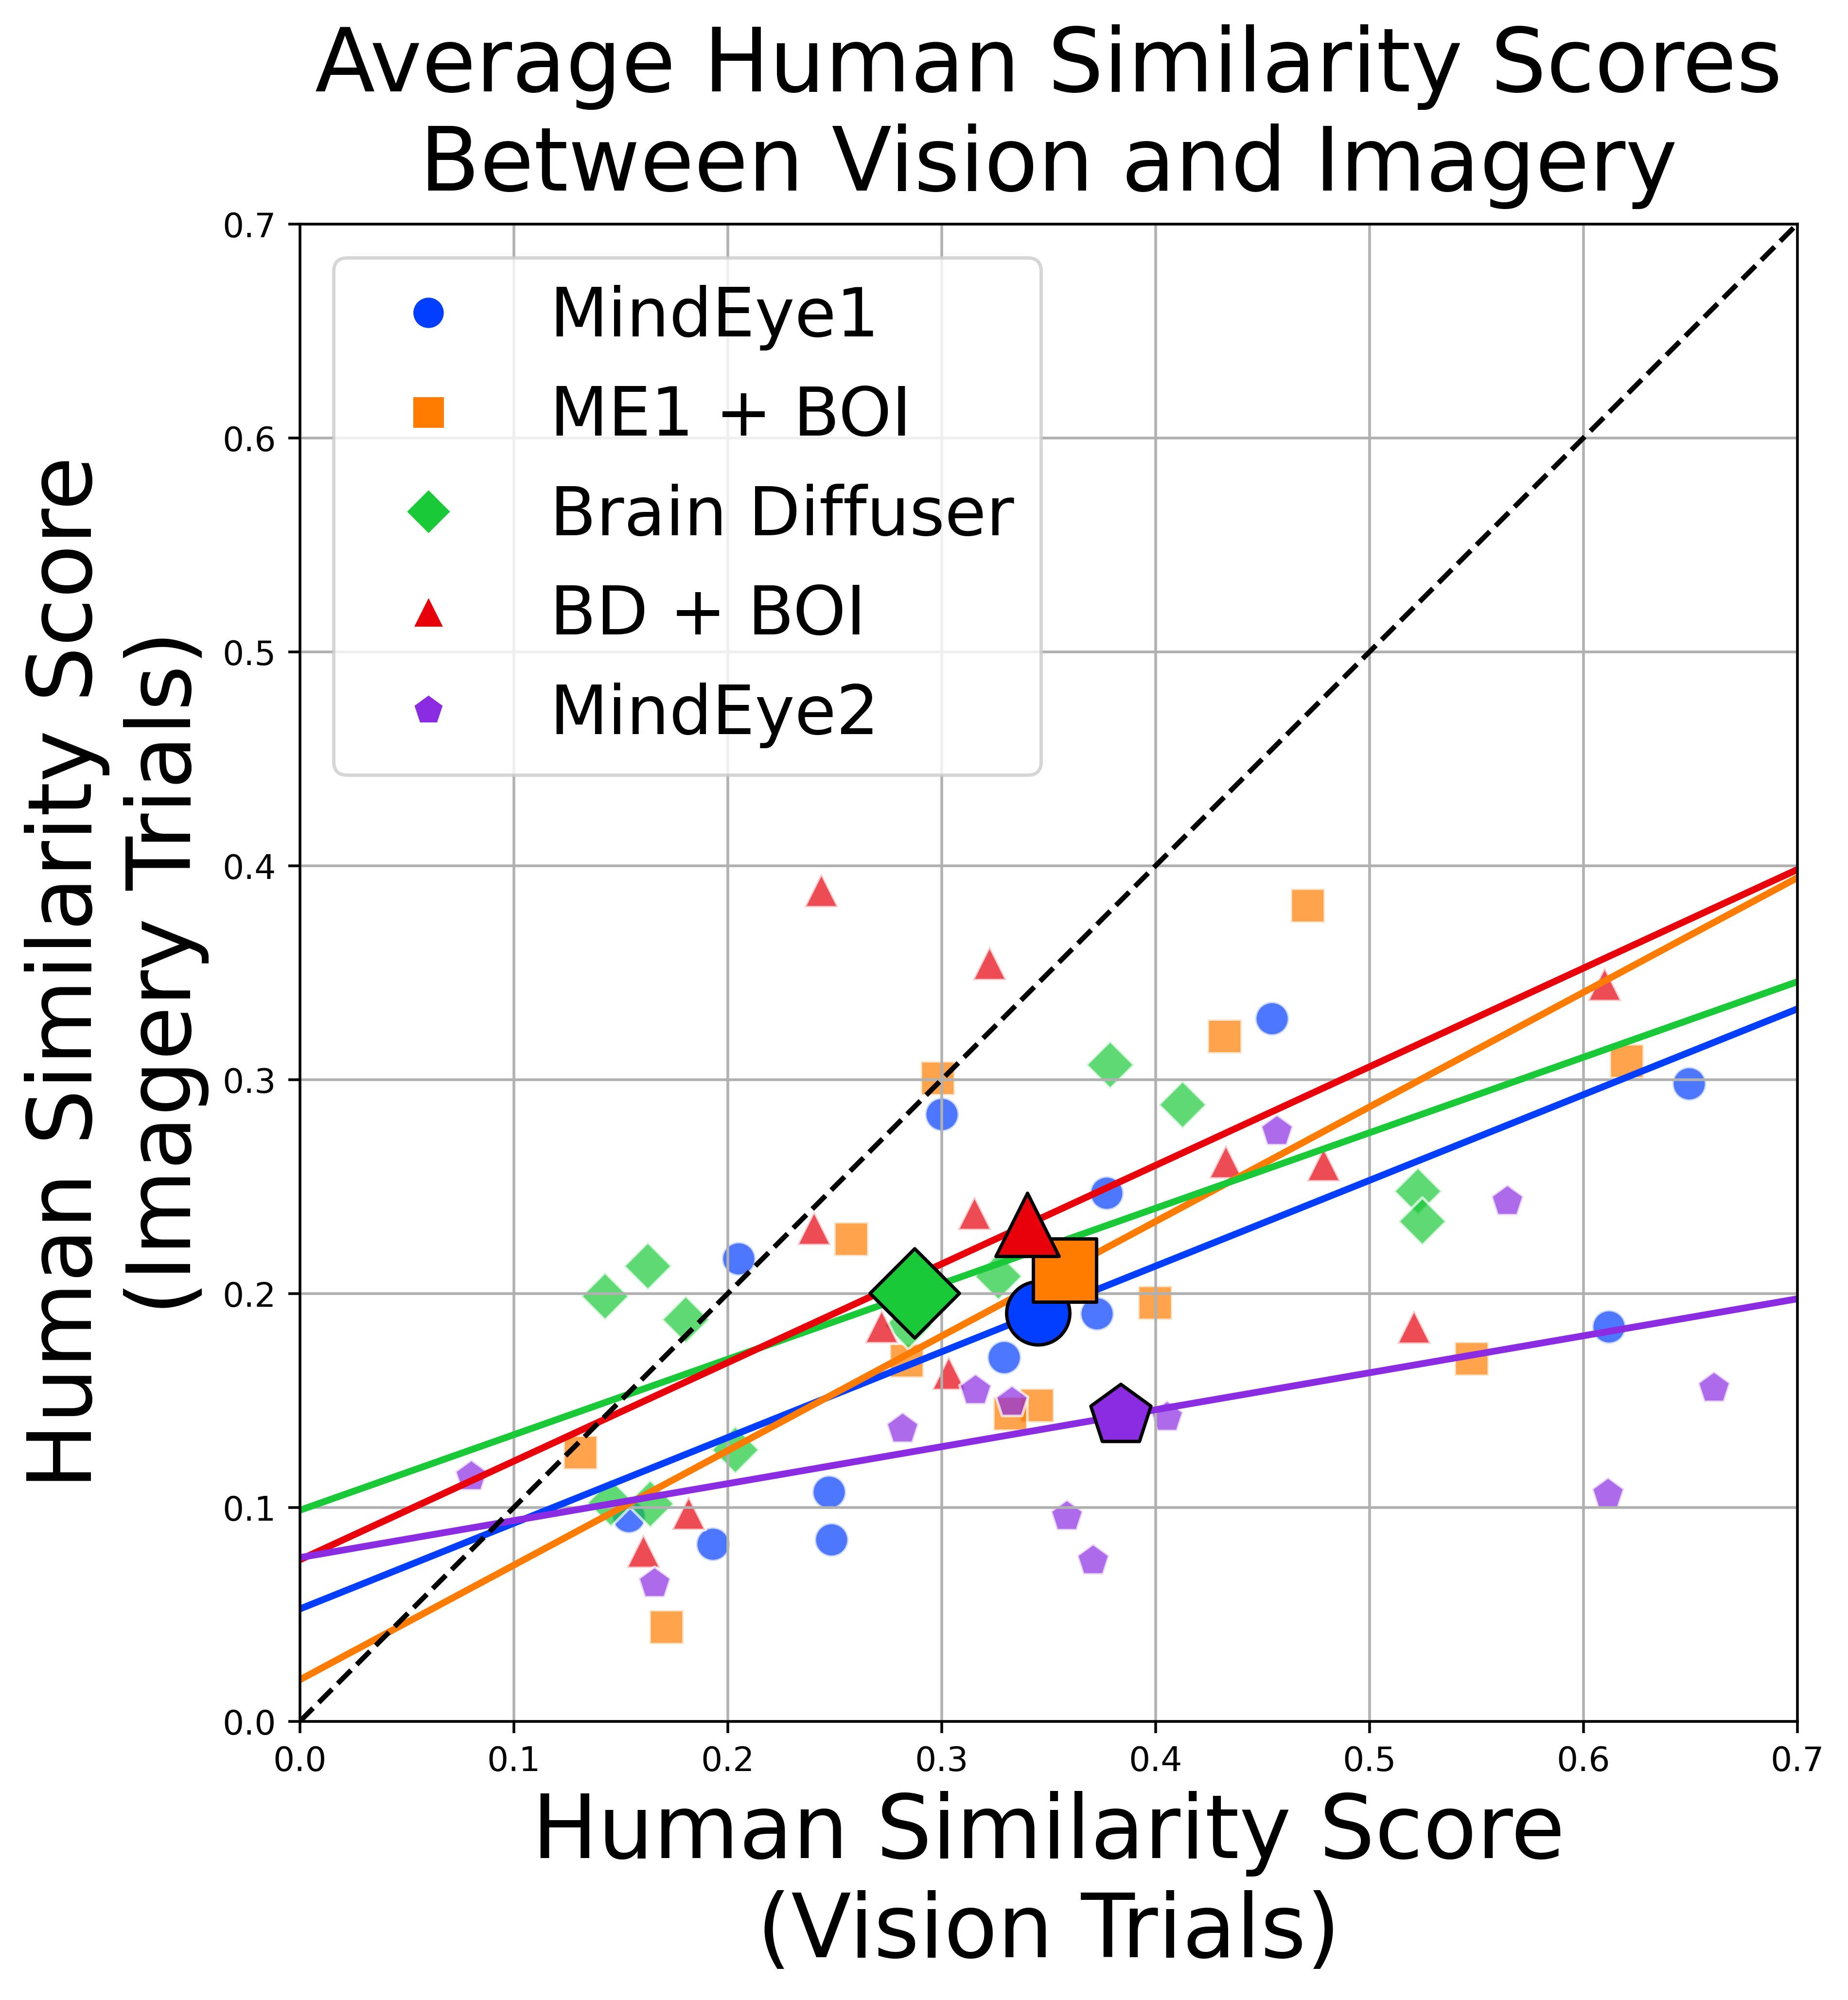

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['method'] != 'tagaki') & (human_df['experiment'] == 2)]
# Grouping and averaging
grouped_df = human_df.groupby(['method', 'sample']).mean().reset_index()

# Define a clear mapping for method display names in the legend
method_display_names = {
    "mindeye": "MindEye1",
    "boi-v2.1": "ME1 + BOI",
    "braindiffuser": "Brain Diffuser",
    "boi-v2.3": "BD + BOI",
    "mindeye2": "MindEye2"
}

# Prepare the plot
fig, ax = plt.subplots(figsize=(8, 8), dpi=500)  # Create a square figure
bright_palette = sns.color_palette('bright', len(method_display_names))
markers = ['o', 's', 'D', '^', 'p', '*']

# First, plot the scatter and PCA lines for each method
for i, (method_code, method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[grouped_df['method'] == method_code]
    # Scatter plot for individual points
    sns.scatterplot(data=method_data, x='target_similarity', y='distractor_similarity', color=bright_palette[i], 
                    label=method_display, s=100, marker=markers[i], alpha=0.7, ax=ax)

    # PCA for best fit line
    pca = PCA(n_components=2)
    points = method_data[['target_similarity', 'distractor_similarity']].dropna()
    pca.fit(points)
    center = pca.mean_
    pc1 = pca.components_[0]
    line_x = np.linspace(points['target_similarity'].min() - 0.5, points['target_similarity'].max() + 0.5, 2)
    line_y = (pc1[1] / pc1[0]) * (line_x - center[0]) + center[1]
    ax.plot(line_x, line_y, color=bright_palette[i], linewidth=2)

# Then, plot the large dots for the mean of each method, ensuring they appear on top
for i, (method_code, method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[grouped_df['method'] == method_code]
    avg_target_similarity = method_data['target_similarity'].mean()
    avg_distractor_similarity = method_data['distractor_similarity'].mean()
    ax.scatter(avg_target_similarity, avg_distractor_similarity, color=bright_palette[i], marker=markers[i], s=350, edgecolors='black', zorder=5)

ax.set_title('Average Human Similarity Scores\nBetween Vision and Imagery', pad=10, fontsize=26)
ax.set_xlabel('Human Similarity Score\n(Vision Trials)', fontsize=26)
ax.set_ylabel('Human Similarity Score\n(Imagery Trials)', fontsize=26)
plt.tight_layout()
ax.grid(True)
ax.set_xlim(0, 0.7)
ax.set_ylim(0, 0.7)
ax.set_aspect('equal', adjustable='box')
ax.plot([0, 0.7], [0, 0.7], 'k--')  # Line at unity

# Adjusting legend to make sure it represents the latest plotted elements correctly
handles, labels = ax.get_legend_handles_labels()
# Ensuring that new handles created for the legend represent the latest plot elements with the correct zorder
new_handles = [plt.Line2D([], [], marker=marker, color='w', markerfacecolor=bright_palette[i], markersize=10, alpha=1) for i, marker in enumerate(markers[:len(method_display_names)])]
ax.legend(new_handles, labels[:len(method_display_names)], bbox_to_anchor=(0, 1), loc='upper left', fontsize=20)

plt.show()


/tmp/ipykernel_20057/1891890381.py:5: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = human_df.groupby(['method', 'sample', 'mode']).mean().reset_index()


12
12
12
12


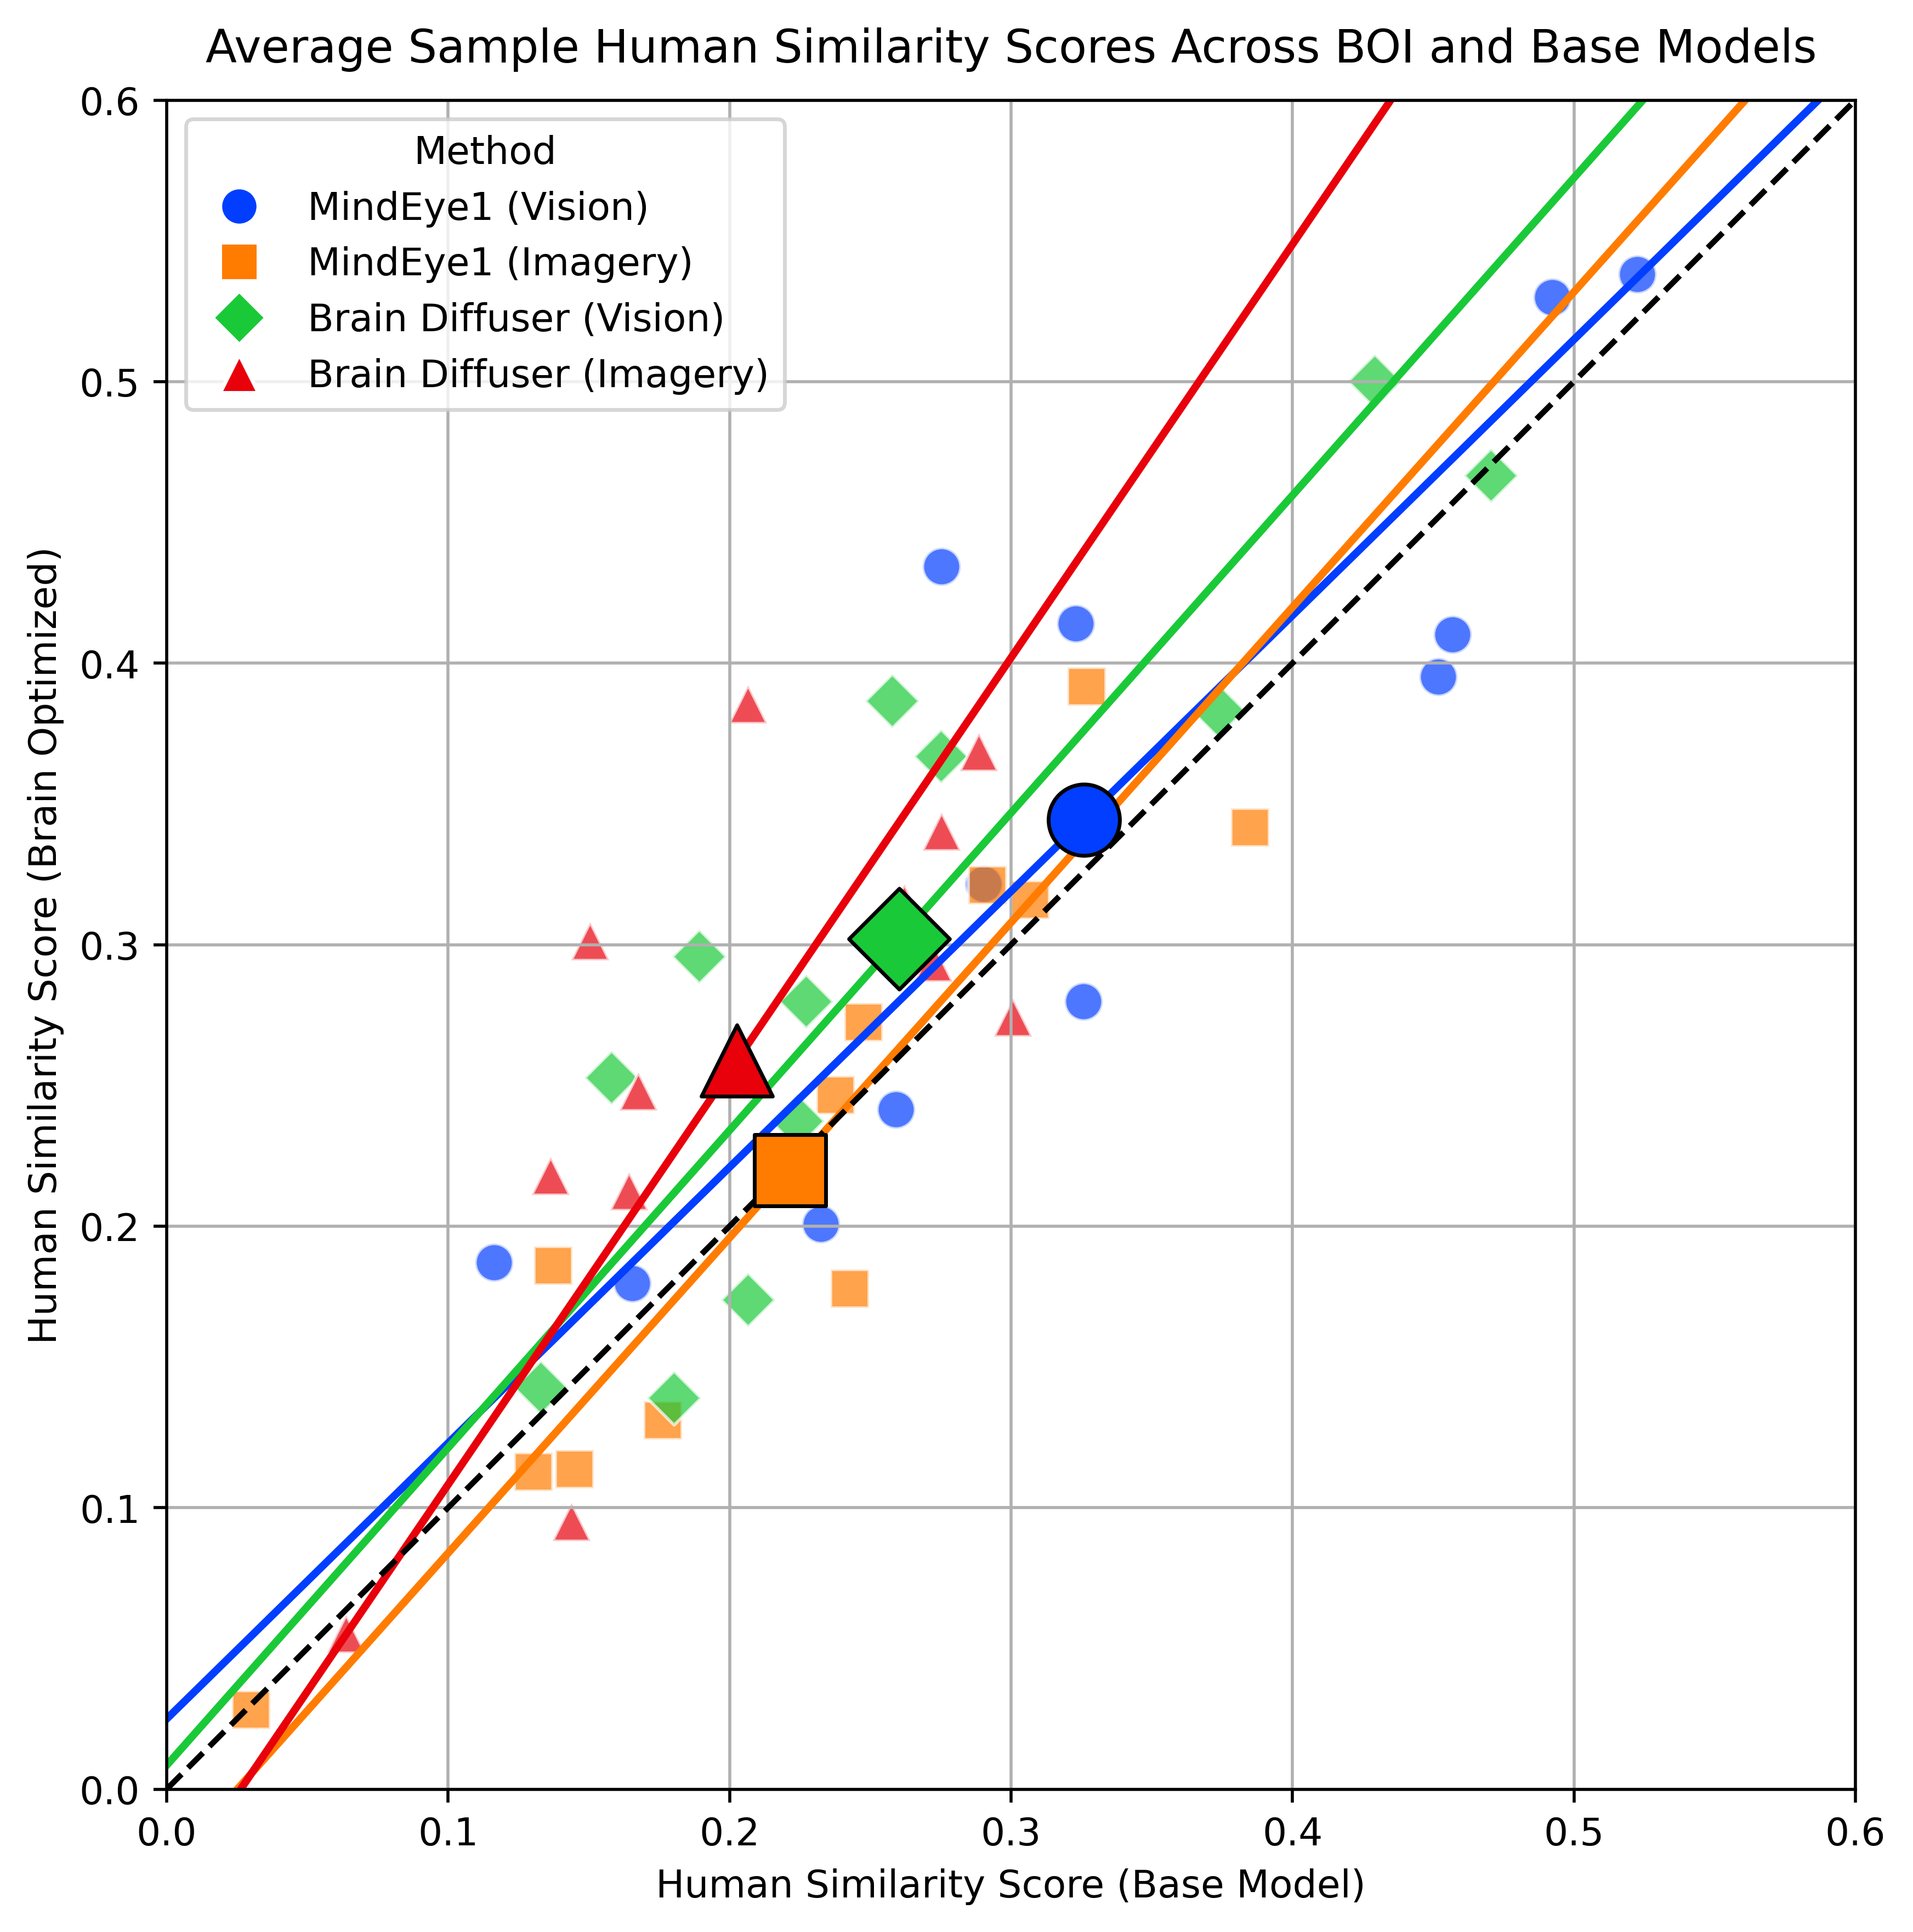

In [52]:

human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['experiment'] == 3)]
# Grouping and averaging
grouped_df = human_df.groupby(['method', 'sample', 'mode']).mean().reset_index()

# Define a clear mapping for method display names in the legend
method_display_names = {
    ("mindeye", "vision"): "MindEye1 (Vision)",
    ("mindeye", "imagery"): "MindEye1 (Imagery)",
    ("braindiffuser", "vision"): "Brain Diffuser (Vision)",
    ("braindiffuser", "imagery"): "Brain Diffuser (Imagery)"
}

# Prepare the plot
plt.figure(figsize=(8, 8),dpi=500)
bright_palette = sns.color_palette('bright', len(method_display_names))
markers = ['o', 's', 'D', '^', 'p', '*']

# Plot scatter and PCA lines for each method and mode combination
for i, ((method_code, mode), method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[(grouped_df['method'] == method_code) & (grouped_df['mode'] == mode)]
    # Scatter plot for individual points
    sns.scatterplot(data=method_data, y='target_similarity', x='distractor_similarity', color=bright_palette[i], 
                    label=method_display, s=100, marker=markers[i], alpha=0.7)

    # PCA for best fit line
    pca = PCA(n_components=2)
    points = method_data[['distractor_similarity', 'target_similarity']].dropna()

    pca.fit(points)
    center = pca.mean_
    pc1 = pca.components_[0]
    line_x = np.linspace(points['target_similarity'].max() + 0.5, points['target_similarity'].min() - 0.5, 2)
    line_y = (pc1[1] / pc1[0]) * (line_x - center[0]) + center[1]
    plt.plot(line_x, line_y, color=bright_palette[i], linewidth=2)

# Then, plot the large dots for the mean of each method, ensuring they appear on top
for i, ((method_code, mode), method_display) in enumerate(method_display_names.items()):
    method_data = grouped_df[(grouped_df['method'] == method_code) & (grouped_df['mode'] == mode)]
    avg_target_similarity = method_data['target_similarity'].mean()
    avg_distractor_similarity = method_data['distractor_similarity'].mean()
    plt.scatter(avg_distractor_similarity, avg_target_similarity, color=bright_palette[i], marker=markers[i], s=350, edgecolors='black', zorder=5)

plt.title('Average Sample Human Similarity Scores Across BOI and Base Models', pad=10)
plt.ylabel('Human Similarity Score (Brain Optimized)')
plt.xlabel('Human Similarity Score (Base Model)')
plt.xlim(0, 0.6)
plt.ylim(0, 0.6)
plt.gca().set_aspect('equal', adjustable='box')
plt.plot([0, 0.6], [0, 0.6], 'k--')  # Line at unity

# Adjusting legend to make sure it represents the latest plotted elements correctly
handles, labels = plt.gca().get_legend_handles_labels()
# Ensuring that new handles created for the legend represent the latest plot elements with the correct zorder
new_handles = [plt.Line2D([], [], marker=marker, color='w', markerfacecolor=bright_palette[i], markersize=10, alpha=1) for i, marker in enumerate(markers[:len(method_display_names)])]
plt.legend(new_handles, labels[:len(method_display_names)], title='Method', bbox_to_anchor=(0, 1), loc='upper left')

plt.grid(True)
plt.show()

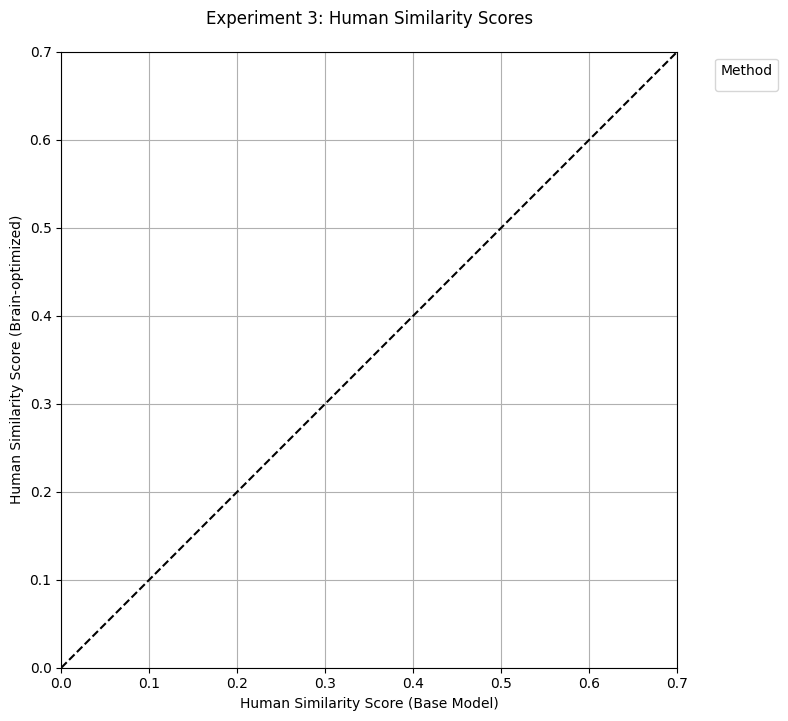

In [18]:
# Correcting the approach to use actual method identifiers for filtering and plotting
plt.figure(figsize=(8, 8))

# Assuming actual method identifiers in the dataframe might differ from the "camera-ready" names
# Let's use a hypothetical correct list of method identifiers for Experiment 3
actual_methods_exp3 = ['mindeye', 'braindiffuser']  # Example identifiers

# Re-creating the color palette and markers for the corrected method list
corrected_palette = sns.color_palette('bright', len(actual_methods_exp3))
corrected_markers = ['o', 'D']  # Example markers for each method

line_data_corrected = {}

# Filtering for Experiment 3 again with corrected identifiers
exp3_corrected_df = human_df[human_df['experiment'] == 3]

# Plotting each method with actual identifiers
for i, method in enumerate(actual_methods_exp3):
    method_data = exp3_corrected_df[exp3_corrected_df['method'] == method]
    if not method_data.empty:  # Ensuring method data is not empty
        m, b = np.polyfit(method_data['distractor_similarity'], method_data['target_similarity'], 1)
        line_data_corrected[method] = (m, b)

        sns.scatterplot(data=method_data, x='distractor_similarity', y='target_similarity', color=corrected_palette[i], 
                        label=method, s=100, marker=corrected_markers[i], alpha=0.7)
        
        avg_distractor_similarity = method_data['distractor_similarity'].mean()
        avg_target_similarity = method_data['target_similarity'].mean()
        plt.scatter(avg_distractor_similarity, avg_target_similarity, color=corrected_palette[i], marker=corrected_markers[i], s=350, edgecolors='black')

# Adding fitted lines with corrected identifiers
for method in actual_methods_exp3:
    if method in line_data_corrected:
        m, b = line_data_corrected[method]
        plt.plot([0, 0.7], [m*0 + b, m*0.7 + b], color=corrected_palette[actual_methods_exp3.index(method)], linewidth=2)

# Adjusting title, labels, and axes for the corrected plot
plt.title('Experiment 3: Human Similarity Scores', pad=20)
plt.xlabel('Human Similarity Score (Base Model)')
plt.ylabel('Human Similarity Score (Brain-optimized)')
plt.xlim(0, 0.7)
plt.ylim(0, 0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.plot([0, 0.7], [0, 0.7], 'k--')

# Correcting the legend with "camera-ready" names
camera_ready_names = {'mindeye': 'MindEye1', 'braindiffuser': 'Brain Diffuser'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [camera_ready_names.get(label, label) for label in labels]
plt.legend(handles, new_labels, title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(True)
plt.show()

In [ ]:
# Preprocessing: Remove rows with NaN values in columns of interest
human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
experiment = 2
data = human_df[human_df['experiment'] == experiment]
data = data.dropna(subset=['target_similarity', 'target_confidence', 'distractor_similarity', 'distractor_confidence'])

# Experiment 1: Target Confidence and Similarity
# Group the data by pID and calculate mean target_confidence and variance in target_similarity
grouped_target = data.groupby('pID').agg({
    'target_confidence': 'mean',
    'target_similarity': 'var'
}).reset_index()
grouped_target.rename(columns={
    'target_confidence': 'mean_target_confidence',
    'target_similarity': 'variance_target_similarity'
}, inplace=True)

# Calculate Pearson correlation coefficient for target
correlation_target = grouped_target['mean_target_confidence'].corr(grouped_target['variance_target_similarity'])

# Experiment 2: Distractor Confidence and Similarity
# Group the data by pID and calculate mean distractor_confidence and variance in distractor_similarity
grouped_distractor = data.groupby('pID').agg({
    'distractor_confidence': 'mean',
    'distractor_similarity': 'var'
}).reset_index()
grouped_distractor.rename(columns={
    'distractor_confidence': 'mean_distractor_confidence',
    'distractor_similarity': 'variance_distractor_similarity'
}, inplace=True)

# Calculate Pearson correlation coefficient for distractor
correlation_distractor = grouped_distractor['mean_distractor_confidence'].corr(grouped_distractor['variance_distractor_similarity'])

# Output the results
print(f"Experiment {experiment}\n")
print("Vision Confidence-Variance Correlation:", correlation_target)
print(grouped_target.describe())
print("\nImagery Confidence-Variance Correlation:", correlation_distractor)
print(grouped_distractor.describe())

#############################################################################################################################
experiment = 3
data = human_df[human_df['experiment'] == experiment]
data = data.dropna(subset=['target_similarity', 'target_confidence', 'distractor_similarity', 'distractor_confidence'])

# Experiment 1: Target Confidence and Similarity
# Group the data by pID and calculate mean target_confidence and variance in target_similarity
grouped_target = data.groupby('pID').agg({
    'target_confidence': 'mean',
    'target_similarity': 'var'
}).reset_index()
grouped_target.rename(columns={
    'target_confidence': 'mean_target_confidence',
    'target_similarity': 'variance_target_similarity'
}, inplace=True)

# Calculate Pearson correlation coefficient for target
correlation_target = grouped_target['mean_target_confidence'].corr(grouped_target['variance_target_similarity'])

# Experiment 2: Distractor Confidence and Similarity
# Group the data by pID and calculate mean distractor_confidence and variance in distractor_similarity
grouped_distractor = data.groupby('pID').agg({
    'distractor_confidence': 'mean',
    'distractor_similarity': 'var'
}).reset_index()
grouped_distractor.rename(columns={
    'distractor_confidence': 'mean_distractor_confidence',
    'distractor_similarity': 'variance_distractor_similarity'
}, inplace=True)

# Calculate Pearson correlation coefficient for distractor
correlation_distractor = grouped_distractor['mean_distractor_confidence'].corr(grouped_distractor['variance_distractor_similarity'])

# Output the results
print(f"Experiment {experiment}")
print("BOI Confidence-Variance Correlation:", correlation_target)
print(grouped_target.describe())
print("\nBase Model Confidence-Variance Correlation:", correlation_distractor)
print(grouped_distractor.describe())

Experiment 2

Vision Confidence-Variance Correlation: 0.13877954276529195
              pID  mean_target_confidence  variance_target_similarity
count  263.000000              263.000000                  263.000000
mean   133.235741                0.226253                    0.063444
std     76.894182                0.181947                    0.035053
min      0.000000                0.000000                    0.000374
25%     66.500000                0.084687                    0.040295
50%    134.000000                0.189268                    0.056520
75%    199.500000                0.320352                    0.080922
max    265.000000                0.828817                    0.221023

Imagery Confidence-Variance Correlation: 0.2529911674302423
              pID  mean_distractor_confidence  variance_distractor_similarity
count  263.000000                2.630000e+02                      263.000000
mean   133.235741                2.263163e-01                        0.041436
s

/tmp/ipykernel_62666/1796693609.py:8: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_means = experiment_2_df.groupby(['sample', 'method']).mean().reset_index()


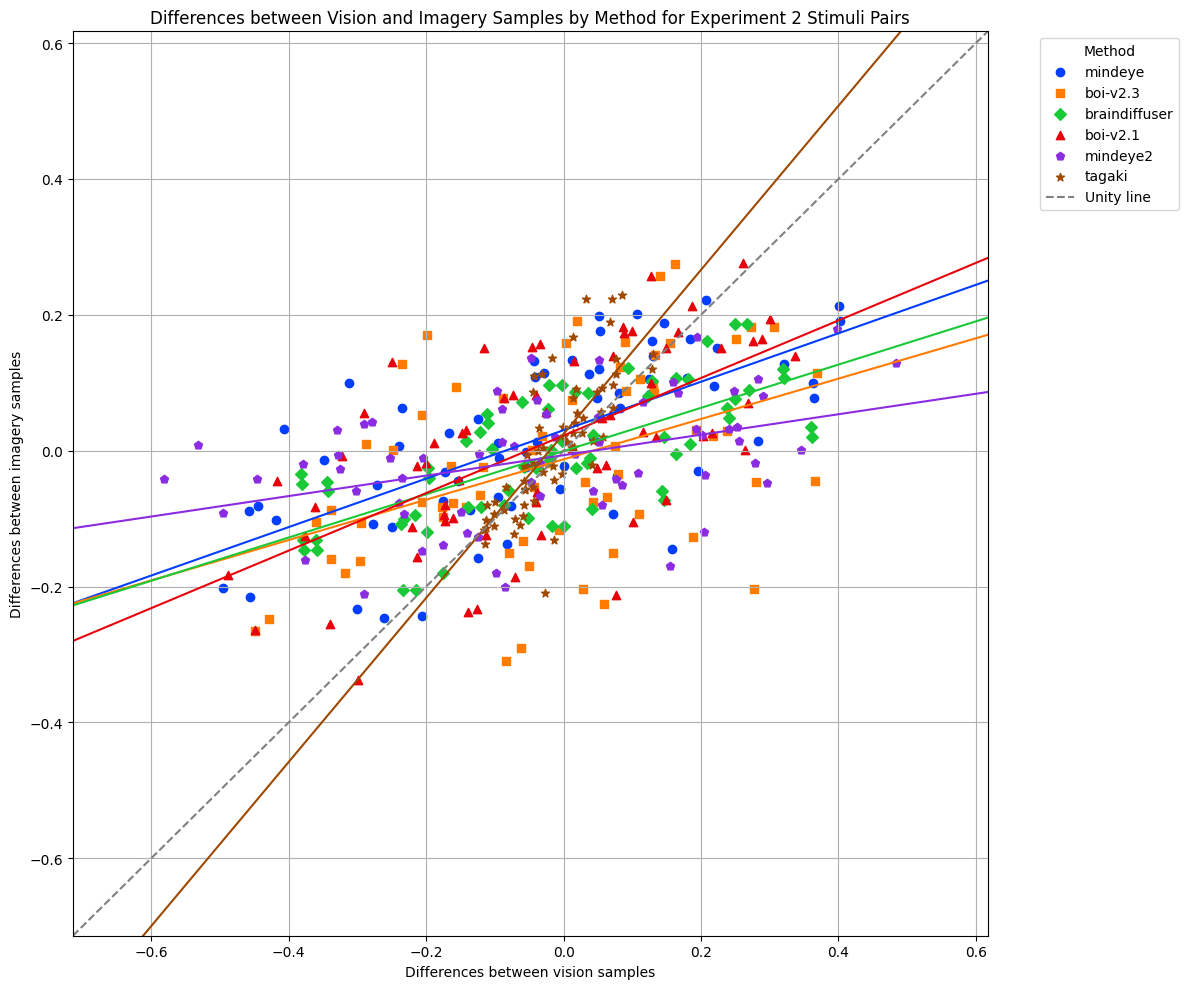

In [32]:
from itertools import combinations
import numpy as np

human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
experiment_2_df = human_df[human_df['experiment'] == 2]

# Calculate means for each sample and method combination
grouped_means = experiment_2_df.groupby(['sample', 'method']).mean().reset_index()

# Define the color palette and markers
methods = experiment_2_df['method'].unique()
bright_palette = sns.color_palette('bright', len(methods))
markers = ['o', 's', 'D', '^', 'p', '*']

# Initialize dictionaries to hold differences
vision_differences_by_method = {}
imagery_differences_by_method = {}

# Calculate differences for each method
for method in methods:
    method_df = grouped_means[grouped_means['method'] == method]
    sample_pairs_method = list(combinations(method_df['sample'].unique(), 2))
    vision_differences = []
    imagery_differences = []

    for pair in sample_pairs_method:
        sample1_df = method_df[method_df['sample'] == pair[0]]
        sample2_df = method_df[method_df['sample'] == pair[1]]
        if not sample1_df.empty and not sample2_df.empty:
            vision_diff = sample1_df['target_similarity'].values[0] - sample2_df['target_similarity'].values[0]
            imagery_diff = sample1_df['distractor_similarity'].values[0] - sample2_df['distractor_similarity'].values[0]

            vision_differences.append(vision_diff)
            imagery_differences.append(imagery_diff)

    vision_differences_by_method[method] = vision_differences
    imagery_differences_by_method[method] = imagery_differences

# Plot configuration
plt.figure(figsize=(12, 10))
x_values_all = np.concatenate([item for item in vision_differences_by_method.values()])
y_values_all = np.concatenate([item for item in imagery_differences_by_method.values()])
pad = (max(x_values_all.max(), y_values_all.max()) - min(x_values_all.min(), y_values_all.min())) * 0.25 / 2
min_val = min(x_values_all.min(), y_values_all.min()) - pad
max_val = max(x_values_all.max(), y_values_all.max()) + pad

for i, method in enumerate(methods):
    plt.scatter(vision_differences_by_method[method], imagery_differences_by_method[method], label=method, color=bright_palette[i], marker=markers[i % len(markers)])
    z = np.polyfit(vision_differences_by_method[method], imagery_differences_by_method[method], 1)
    p = np.poly1d(z)
    plt.plot([min_val, max_val], p([min_val, max_val]), linestyle='-', color=bright_palette[i])

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color='gray', label='Unity line')
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title('Differences between Vision and Imagery Samples by Method for Experiment 2 Stimuli Pairs')
plt.ylabel('Differences between imagery samples')
plt.xlabel('Differences between vision samples')
plt.grid(True)
plt.legend(title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

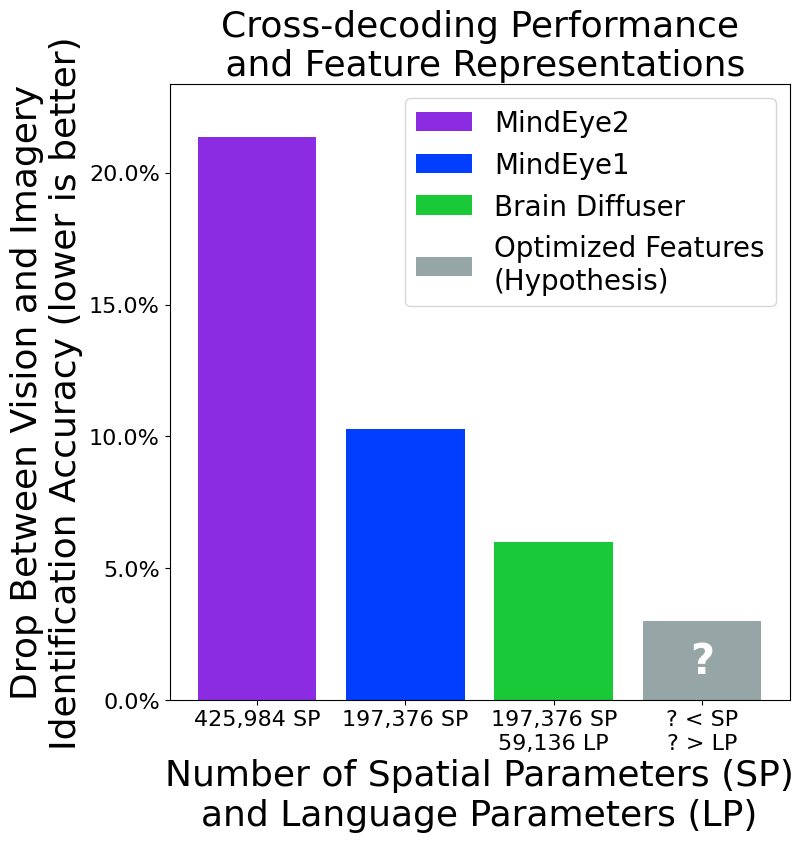

In [4]:

methods = ["MindEye2", "MindEye1", "Brain Diffuser", "Optimized Features\n(Hypothesis)"]
dimensions = [425984, 197376, 59136]
vision_scores = np.array([84.25, 85.17, 81.49])  # np.nan for unknown value
imagery_scores = np.array([62.89, 74.89, 75.48])  # np.nan for unknown value
diff = vision_scores - imagery_scores
bright_palette = sns.color_palette('bright', 5)

bar_labels = ["425,984 SP", "197,376 SP", "197,376 SP\n59,136 LP", "? < SP\n? > LP"]

# Plotting
fig, ax = plt.subplots(figsize=(8, 8))  # Set the figure size to be square

bars = ax.bar(methods[:-1], diff, color=[bright_palette[4], bright_palette[0], bright_palette[2]])

# Adding the unknown value bar with a small placeholder value
future_bar = ax.bar(methods[-1], 3, color='darkslategray', alpha=0.5)

# Adding the future bar to the bars list
bars = list(bars) + list(future_bar)

# Adding labels and title
ax.set_ylabel('Drop Between Vision and Imagery\nIdentification Accuracy (lower is better)', fontsize=26)
ax.set_xlabel('Number of Spatial Parameters (SP)\nand Language Parameters (LP)', fontsize=26)
ax.set_title('Cross-decoding Performance\n and Feature Representations', fontsize=26)
ax.set_ylim([0, max(diff[:-1]) + 2])

# Adding value labels at the bottom of the bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.annotate("",
                xy=(bar.get_x() + bar.get_width() / 2, 0),  # Position at the bottom
                xytext=(0, -20),  # Offset downwards
                textcoords="offset points",
                ha='center', va='top')

# Change the x-axis tick labels to bar_labels
ax.set_xticks(np.arange(len(bar_labels)))
ax.set_xticklabels(bar_labels, fontsize=16)
# Format y-axis ticks as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.yticks(fontsize=16)
# Creating the legend
ax.legend(bars, methods, loc='upper right', fontsize=20)
plt.text(3, 1, "?", ha = 'center', fontsize=30, color='white',weight='bold')
# Setting the aspect ratio to be square
ax.set_aspect(aspect='auto', adjustable='box')

plt.show()

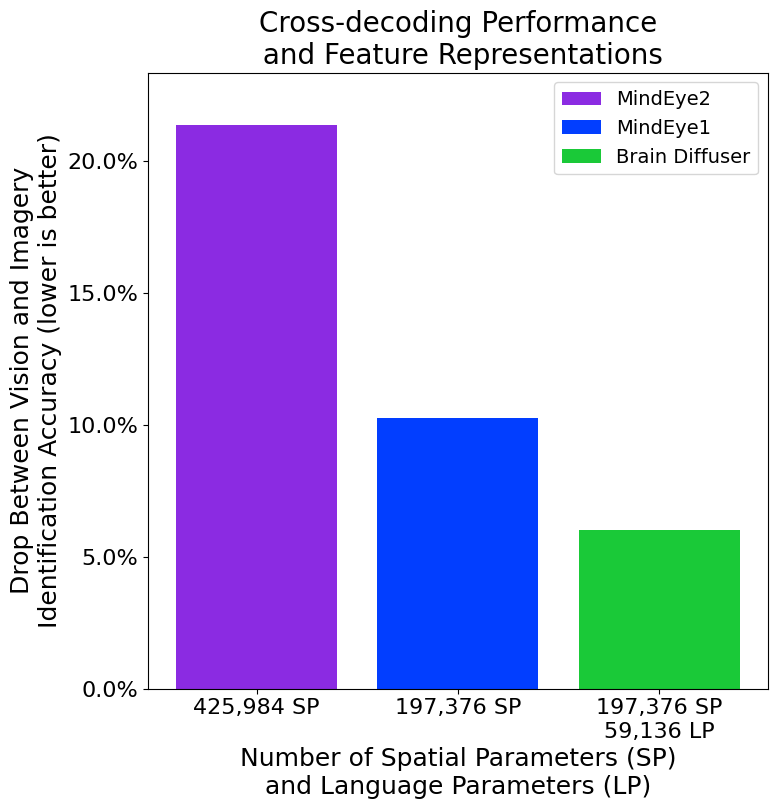

In [4]:

methods = ["MindEye2", "MindEye1", "Brain Diffuser"]
dimensions = [425984, 197376, 59136]
vision_scores = np.array([84.25, 85.17, 81.49])  # np.nan for unknown value
imagery_scores = np.array([62.89, 74.89, 75.48])  # np.nan for unknown value
diff = vision_scores - imagery_scores
bright_palette = sns.color_palette('bright', 5)

bar_labels = ["425,984 SP", "197,376 SP", "197,376 SP\n59,136 LP"]

# Plotting
fig, ax = plt.subplots(figsize=(8, 8))  # Set the figure size to be square

bars = ax.bar(methods, diff, color=[bright_palette[4], bright_palette[0], bright_palette[2]])

# Adding labels and title
ax.set_ylabel('Drop Between Vision and Imagery\nIdentification Accuracy (lower is better)', fontsize=18)
ax.set_xlabel('Number of Spatial Parameters (SP)\nand Language Parameters (LP)', fontsize=18)
ax.set_title('Cross-decoding Performance\n and Feature Representations', fontsize=20)
ax.set_ylim([0, max(diff[:-1]) + 2])

# Adding value labels at the bottom of the bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.annotate("",
                xy=(bar.get_x() + bar.get_width() / 2, 0),  # Position at the bottom
                xytext=(0, -20),  # Offset downwards
                textcoords="offset points",
                ha='center', va='top')

# Change the x-axis tick labels to bar_labels
ax.set_xticks(np.arange(len(bar_labels)))
ax.set_xticklabels(bar_labels, fontsize=16)
# Format y-axis ticks as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.yticks(fontsize=16)
# Creating the legend
ax.legend(bars, methods, loc='upper right', fontsize=14)
# plt.text(3, 1, "?", ha = 'center', fontsize=30, color='white',weight='bold')
# Setting the aspect ratio to be square
ax.set_aspect(aspect='auto', adjustable='box')

plt.show()

Found dataframe for imagery, mindeye, 1, 1
Found dataframe for imagery, mindeye, 1, 2
Found dataframe for imagery, mindeye, 1, 3
Found dataframe for imagery, mindeye, 1, 4
Found dataframe for imagery, mindeye, 1, 5
Found dataframe for imagery, mindeye, 1, 6
Found dataframe for imagery, mindeye, 1, 7
Found dataframe for imagery, mindeye, 1, 8
Found dataframe for imagery, mindeye, 1, 9
Found dataframe for imagery, mindeye, 1, 10
Found dataframe for imagery, mindeye, 1, 11
Found dataframe for imagery, mindeye, 1, 12
Found dataframe for imagery, mindeye, 1, 13
Found dataframe for imagery, mindeye, 1, 14
Found dataframe for imagery, mindeye, 1, 15
Found dataframe for imagery, mindeye, 1, 16
Found dataframe for imagery, mindeye, 2, 1
Found dataframe for imagery, mindeye, 2, 2
Found dataframe for imagery, mindeye, 2, 3
Found dataframe for imagery, mindeye, 2, 4
Found dataframe for imagery, mindeye, 2, 5
Found dataframe for imagery, mindeye, 2, 6
Found dataframe for imagery, mindeye, 2, 7
Foun

/tmp/ipykernel_121600/1089936776.py:41: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  grouped_df = df.groupby(['Mode', 'base_method', 'trial_reps']).mean().reset_index()
/tmp/ipykernel_121600/1089936776.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['Total Metric'] = (filtered_df['Total Metric'] - filtered_df['Total Metric'].min()) / (filtered_df['Total Metric'].max() - filtered_df['Total Metric'].min())


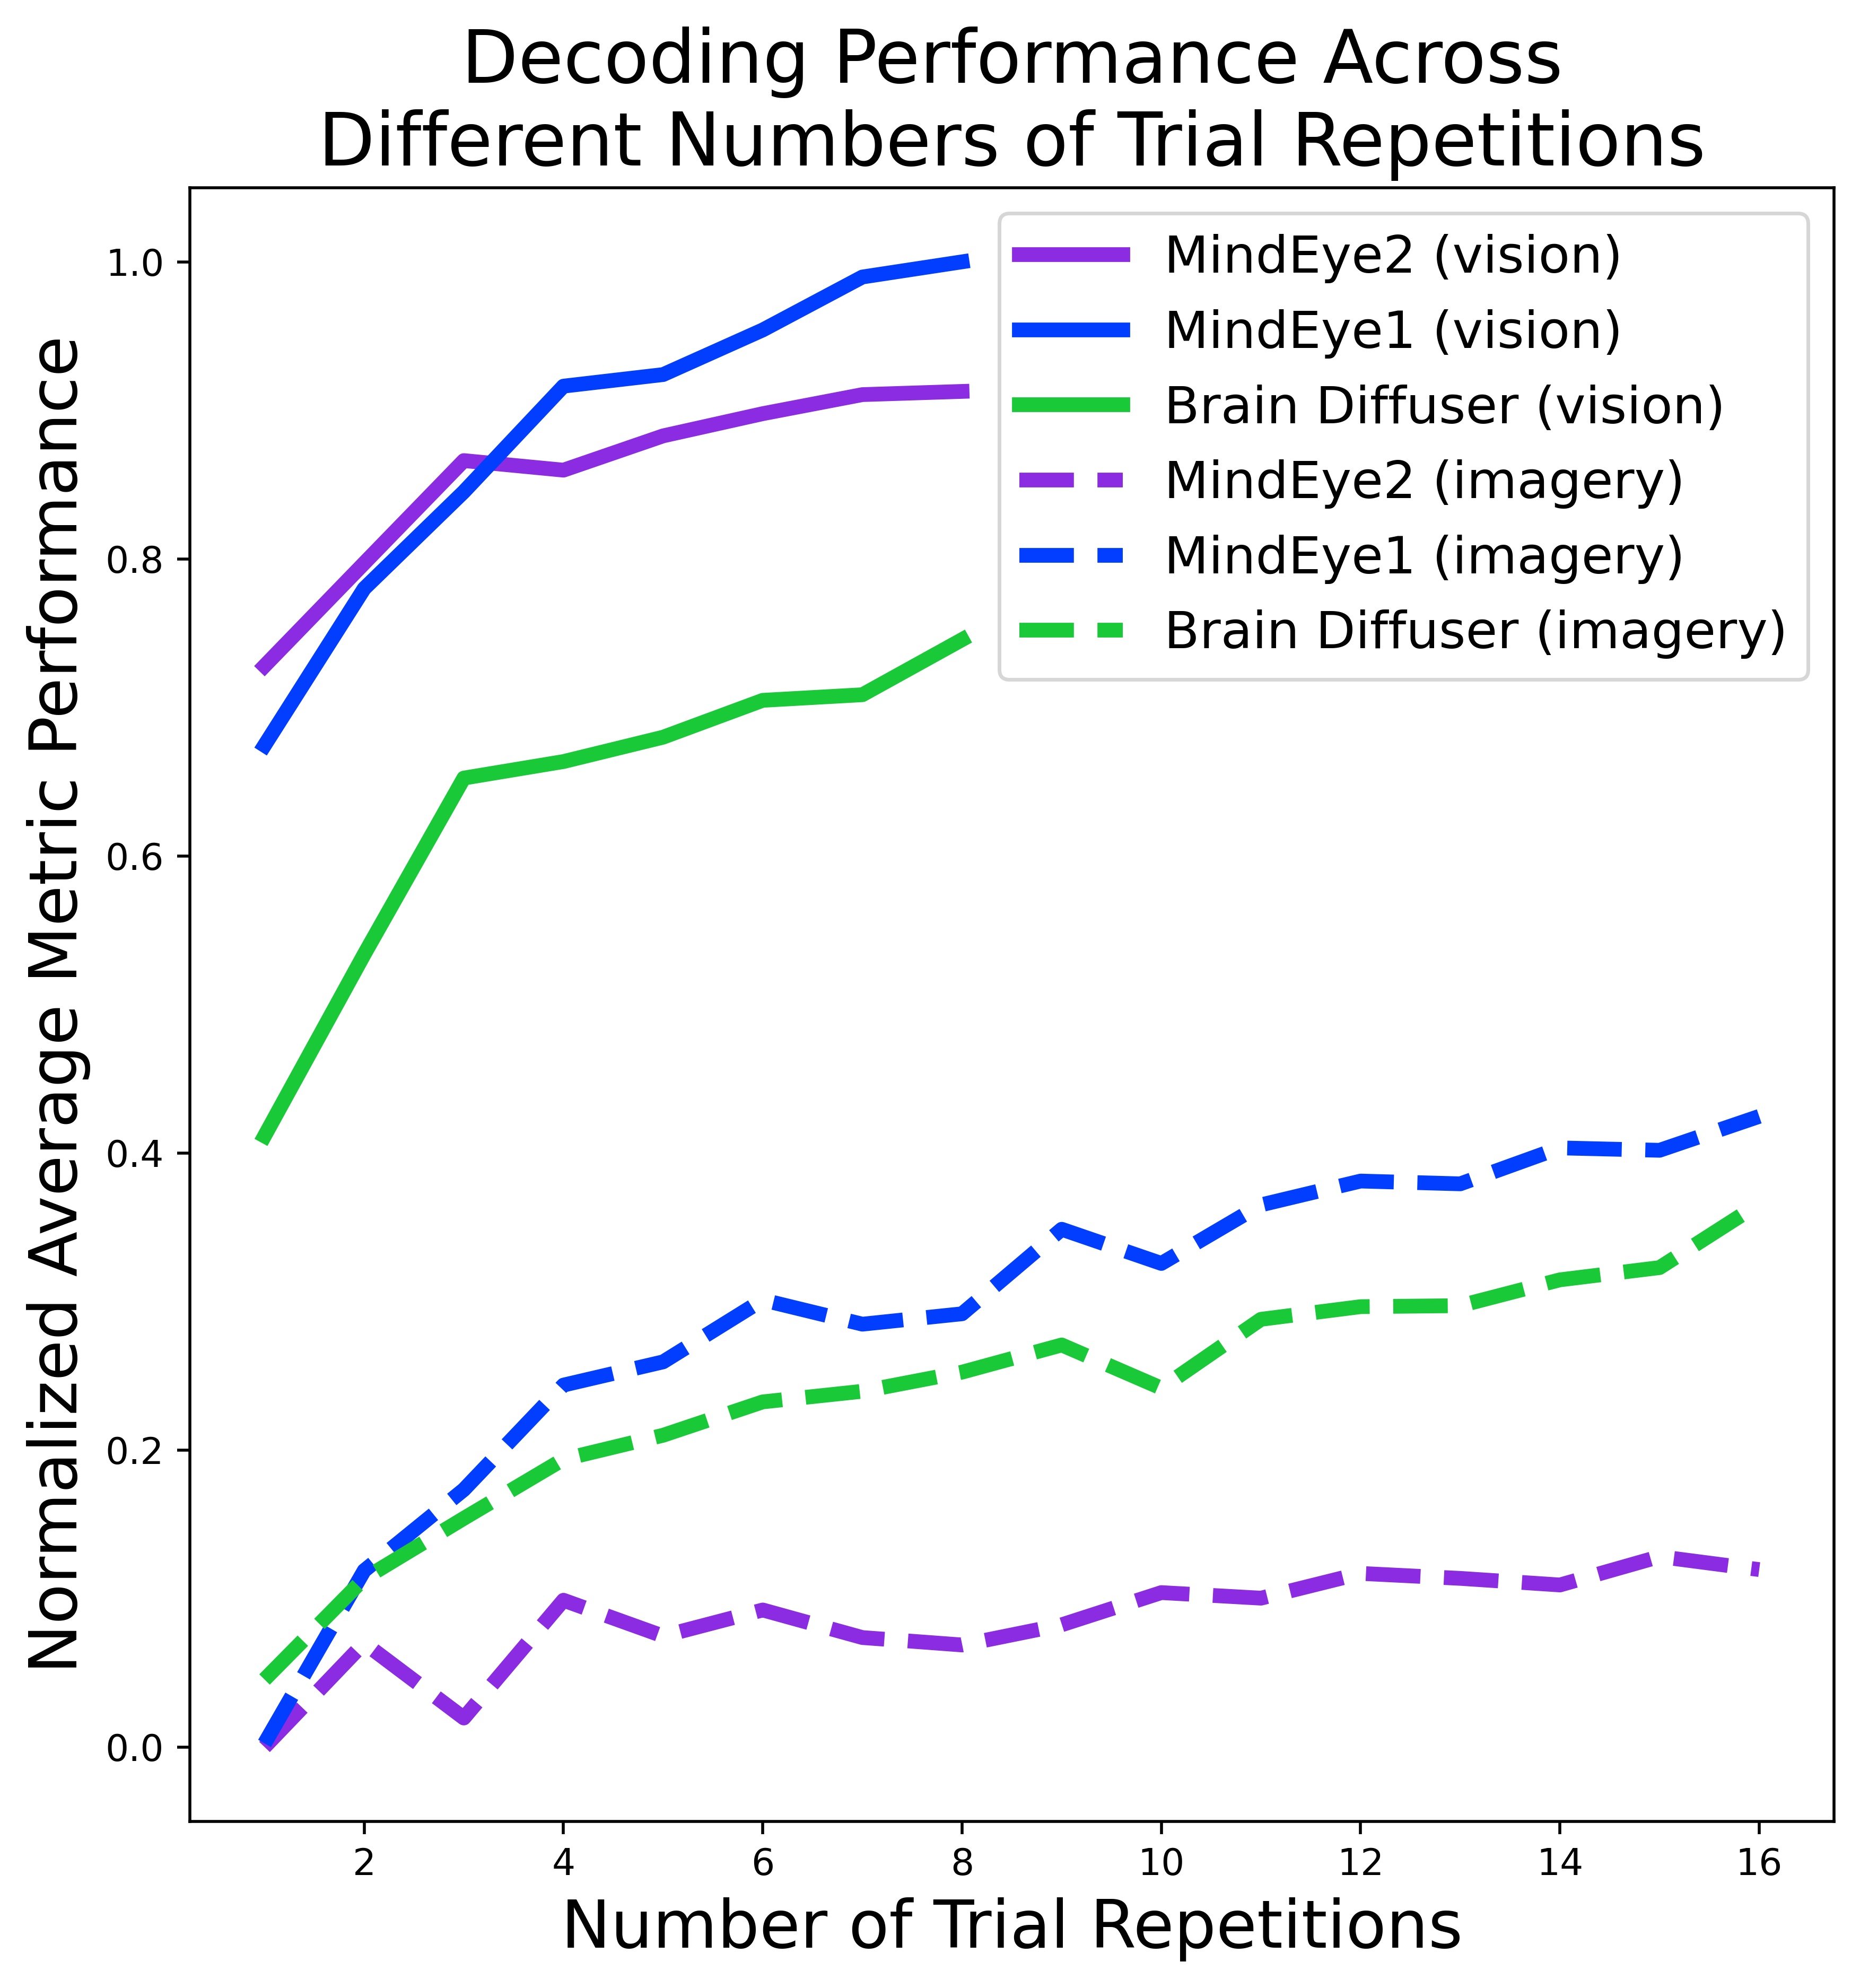

In [8]:
df = pd.DataFrame()
for mode in ['imagery', 'vision']:
    if mode == 'vision':
        trial_rep_list = range(1,9)
    else:
        trial_rep_list = range(1,17)
    for method in ["mindeye", "braindiffuser", "mindeye2"]:
        for subject in [1,2,5,7]:
            for trial_reps in trial_rep_list:
                try:
                    new_df = pd.read_csv(f"output/mental_imagery_paper_b3/{mode}/{method}_{trial_reps}_trial_reps/subject{subject}_statistics_18.csv")
                    new_df['trial_reps'] = trial_reps
                    new_df['base_method'] = method
                    df = pd.concat([df, new_df])
                    print(f"Found dataframe for {mode}, {method}, {subject}, {trial_reps}")
                except:
                    print(f"Dataframe not found for {mode}, {method}, {subject}, {trial_reps}")
print(df)
df = df[(df['ID'] < 12) & (df['Sample Indicator'] == 12)]
# Define the columns to be used for plotting metric norm
columns_to_consider = [
    "Brain Correlation V1",
    "Brain Correlation V2",
    "Brain Correlation V3",
    "Brain Correlation V4",
    "Brain Correlation Higher Visual",
    "Brain Correlation NSD General",
    "AlexNet 2",
    "AlexNet 5",
    "AlexNet 7",
    "CLIP Two-way",
    "Inception V3"
        ]
for metric in columns_to_consider:
    df[metric] = (df[metric] - df[metric].min()) / (df[metric].max() - df[metric].min())

df['Total Metric'] = df[columns_to_consider].sum(axis=1)


# Group the dataframe by mode, method, and trial_reps and calculate the average of Total Metric
grouped_df = df.groupby(['Mode', 'base_method', 'trial_reps']).mean().reset_index()


# Filter the dataframe for the desired columns
filtered_df = grouped_df[['Mode', 'base_method', 'trial_reps', 'Total Metric']]

filtered_df['Total Metric'] = (filtered_df['Total Metric'] - filtered_df['Total Metric'].min()) / (filtered_df['Total Metric'].max() - filtered_df['Total Metric'].min())
plt.figure(figsize=(8, 8), dpi=500)
plt.ylabel('Normalized Average Metric Performance', fontsize=18)
plt.xlabel('Number of Trial Repetitions', fontsize=18)
plt.title('Decoding Performance Across\nDifferent Numbers of Trial Repetitions', fontsize=20)
methods = ["MindEye2", "MindEye1", "Brain Diffuser"]
bright_palette = sns.color_palette('bright', 5)
colors=[bright_palette[4], bright_palette[0], bright_palette[2]]
linestyles=['-', '--']
# Iterate over each combination of mode and method
for m, mode in enumerate(['vision', 'imagery']):
    linestyle=linestyles[m]
    for i, method in enumerate(['mindeye2', 'mindeye', 'braindiffuser']):
        # Filter the dataframe for the specific mode and method
        mode_method_df = filtered_df[(filtered_df['Mode'] == mode) & (filtered_df['base_method'] == method)]
        # Plot the line for the specific mode and method
        plt.plot(mode_method_df['trial_reps'], mode_method_df['Total Metric'], label=f"{methods[i]} ({mode})", color=colors[i], linestyle=linestyle, linewidth=4)

# Add legend
plt.legend(fontsize=14)

# Show the plot
plt.show()

/tmp/ipykernel_64080/2596721251.py:16: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  averaged_data = grouped_data.groupby(['subject', 'mode']).mean().reset_index()


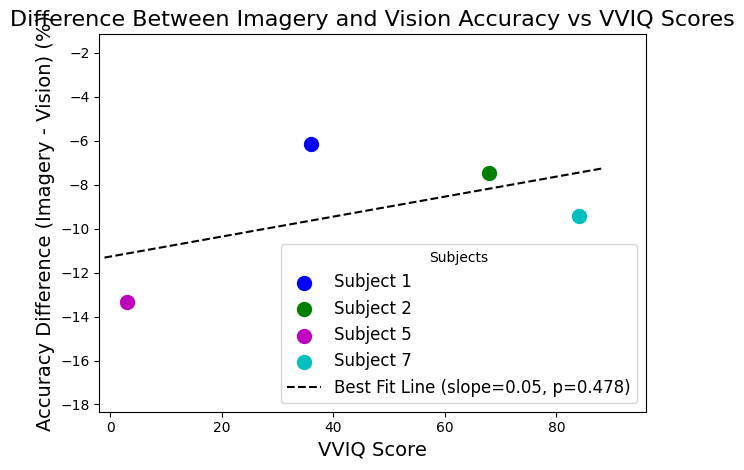

In [4]:
human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')

# Filter and process the dataframe based on the provided code
human_df = human_df[(human_df['experiment'] == 1) & (human_df['method'] != "tagaki") & (human_df['method'] != "mindeye2")]
grouped_data = human_df.groupby(['subject', 'stimtype', 'mode'])['picked_target'].mean().reset_index()
grouped_data.rename(columns={'picked_target': 'Accuracy'}, inplace=True)
grouped_data['Accuracy'] *= 100

# Dictionary of VVIQ scores for each subject
vviq_scores = {1: 36, 2: 68, 3: 91, 4: 76, 5: 3, 6: 61, 7: 84, 8: 36}

# Add VVIQ scores to the grouped data
grouped_data['VVIQ'] = grouped_data['subject'].map(vviq_scores)

# Average across all other values (stimtype, repetitions, methods, samples, etc.)
averaged_data = grouped_data.groupby(['subject', 'mode']).mean().reset_index()

# Pivot the data to get Vision and Imagery scores
pivot_data = averaged_data.pivot(index='subject', columns='mode', values='Accuracy').reset_index()

# Calculate the difference between imagery and vision
pivot_data['Difference'] = pivot_data['imagery'] - pivot_data['vision']

# Extract the relevant subjects
valid_subjects = pivot_data['subject']

# Prepare data for line of best fit
x = [vviq_scores[subject] for subject in valid_subjects]
y = pivot_data['Difference']

# Compute the line of best fit
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

# Create the plot with padding for the axes
fig, ax1 = plt.subplots()

# Plot the data points for each subject
colors = ['b', 'g', 'm', 'c']  # Different colors for each subject
for i, subject in enumerate(valid_subjects):
    ax1.scatter(vviq_scores[subject], pivot_data.loc[pivot_data['subject'] == subject, 'Difference'], 
                color=colors[i], label=f'Subject {int(subject)}', s=100)

# Plot the line of best fit
x_vals = ax1.get_xlim()  # Get the x-axis limits
best_fit_line = [slope * xi + intercept for xi in x_vals]
ax1.plot(x_vals, best_fit_line, color='black', linestyle='--', label=f'Best Fit Line (slope={slope:.2f}, p={p_value:.3f})')

# Set labels and title with increased font size
ax1.set_xlabel('VVIQ Score', fontsize=14)
ax1.set_ylabel('Accuracy Difference (Imagery - Vision) (%)', fontsize=14)
ax1.set_title('Difference Between Imagery and Vision Accuracy vs VVIQ Scores', fontsize=16)

# Add padding to the axes
ax1.set_xlim([min(vviq_scores.values()) - 5, max(vviq_scores.values()) + 5])
ax1.set_ylim([pivot_data['Difference'].min() - 5, pivot_data['Difference'].max() + 5])

# Add legend with integer subject numbers
ax1.legend(title='Subjects', fontsize=12)

# Adjust layout and show plot
plt.tight_layout()
plt.show()



['braindiffuser' 'mindeye' 'boi-v2.3' 'tagaki' 'boi-v2.1' 'mindeye2']
['boi-v2.1' 'boi-v2.3' 'braindiffuser' 'mindeye' 'mindeye2' 'tagaki']
boi-v2.1 0.859538784067086 0.7415966386554622
boi-v2.3 0.8411016949152542 0.7594142259414226
braindiffuser 0.8148936170212766 0.7547568710359408
mindeye 0.8516949152542372 0.7489451476793249
mindeye2 0.8427672955974843 0.6289308176100629
tagaki 0.5189873417721519 0.4957805907172996


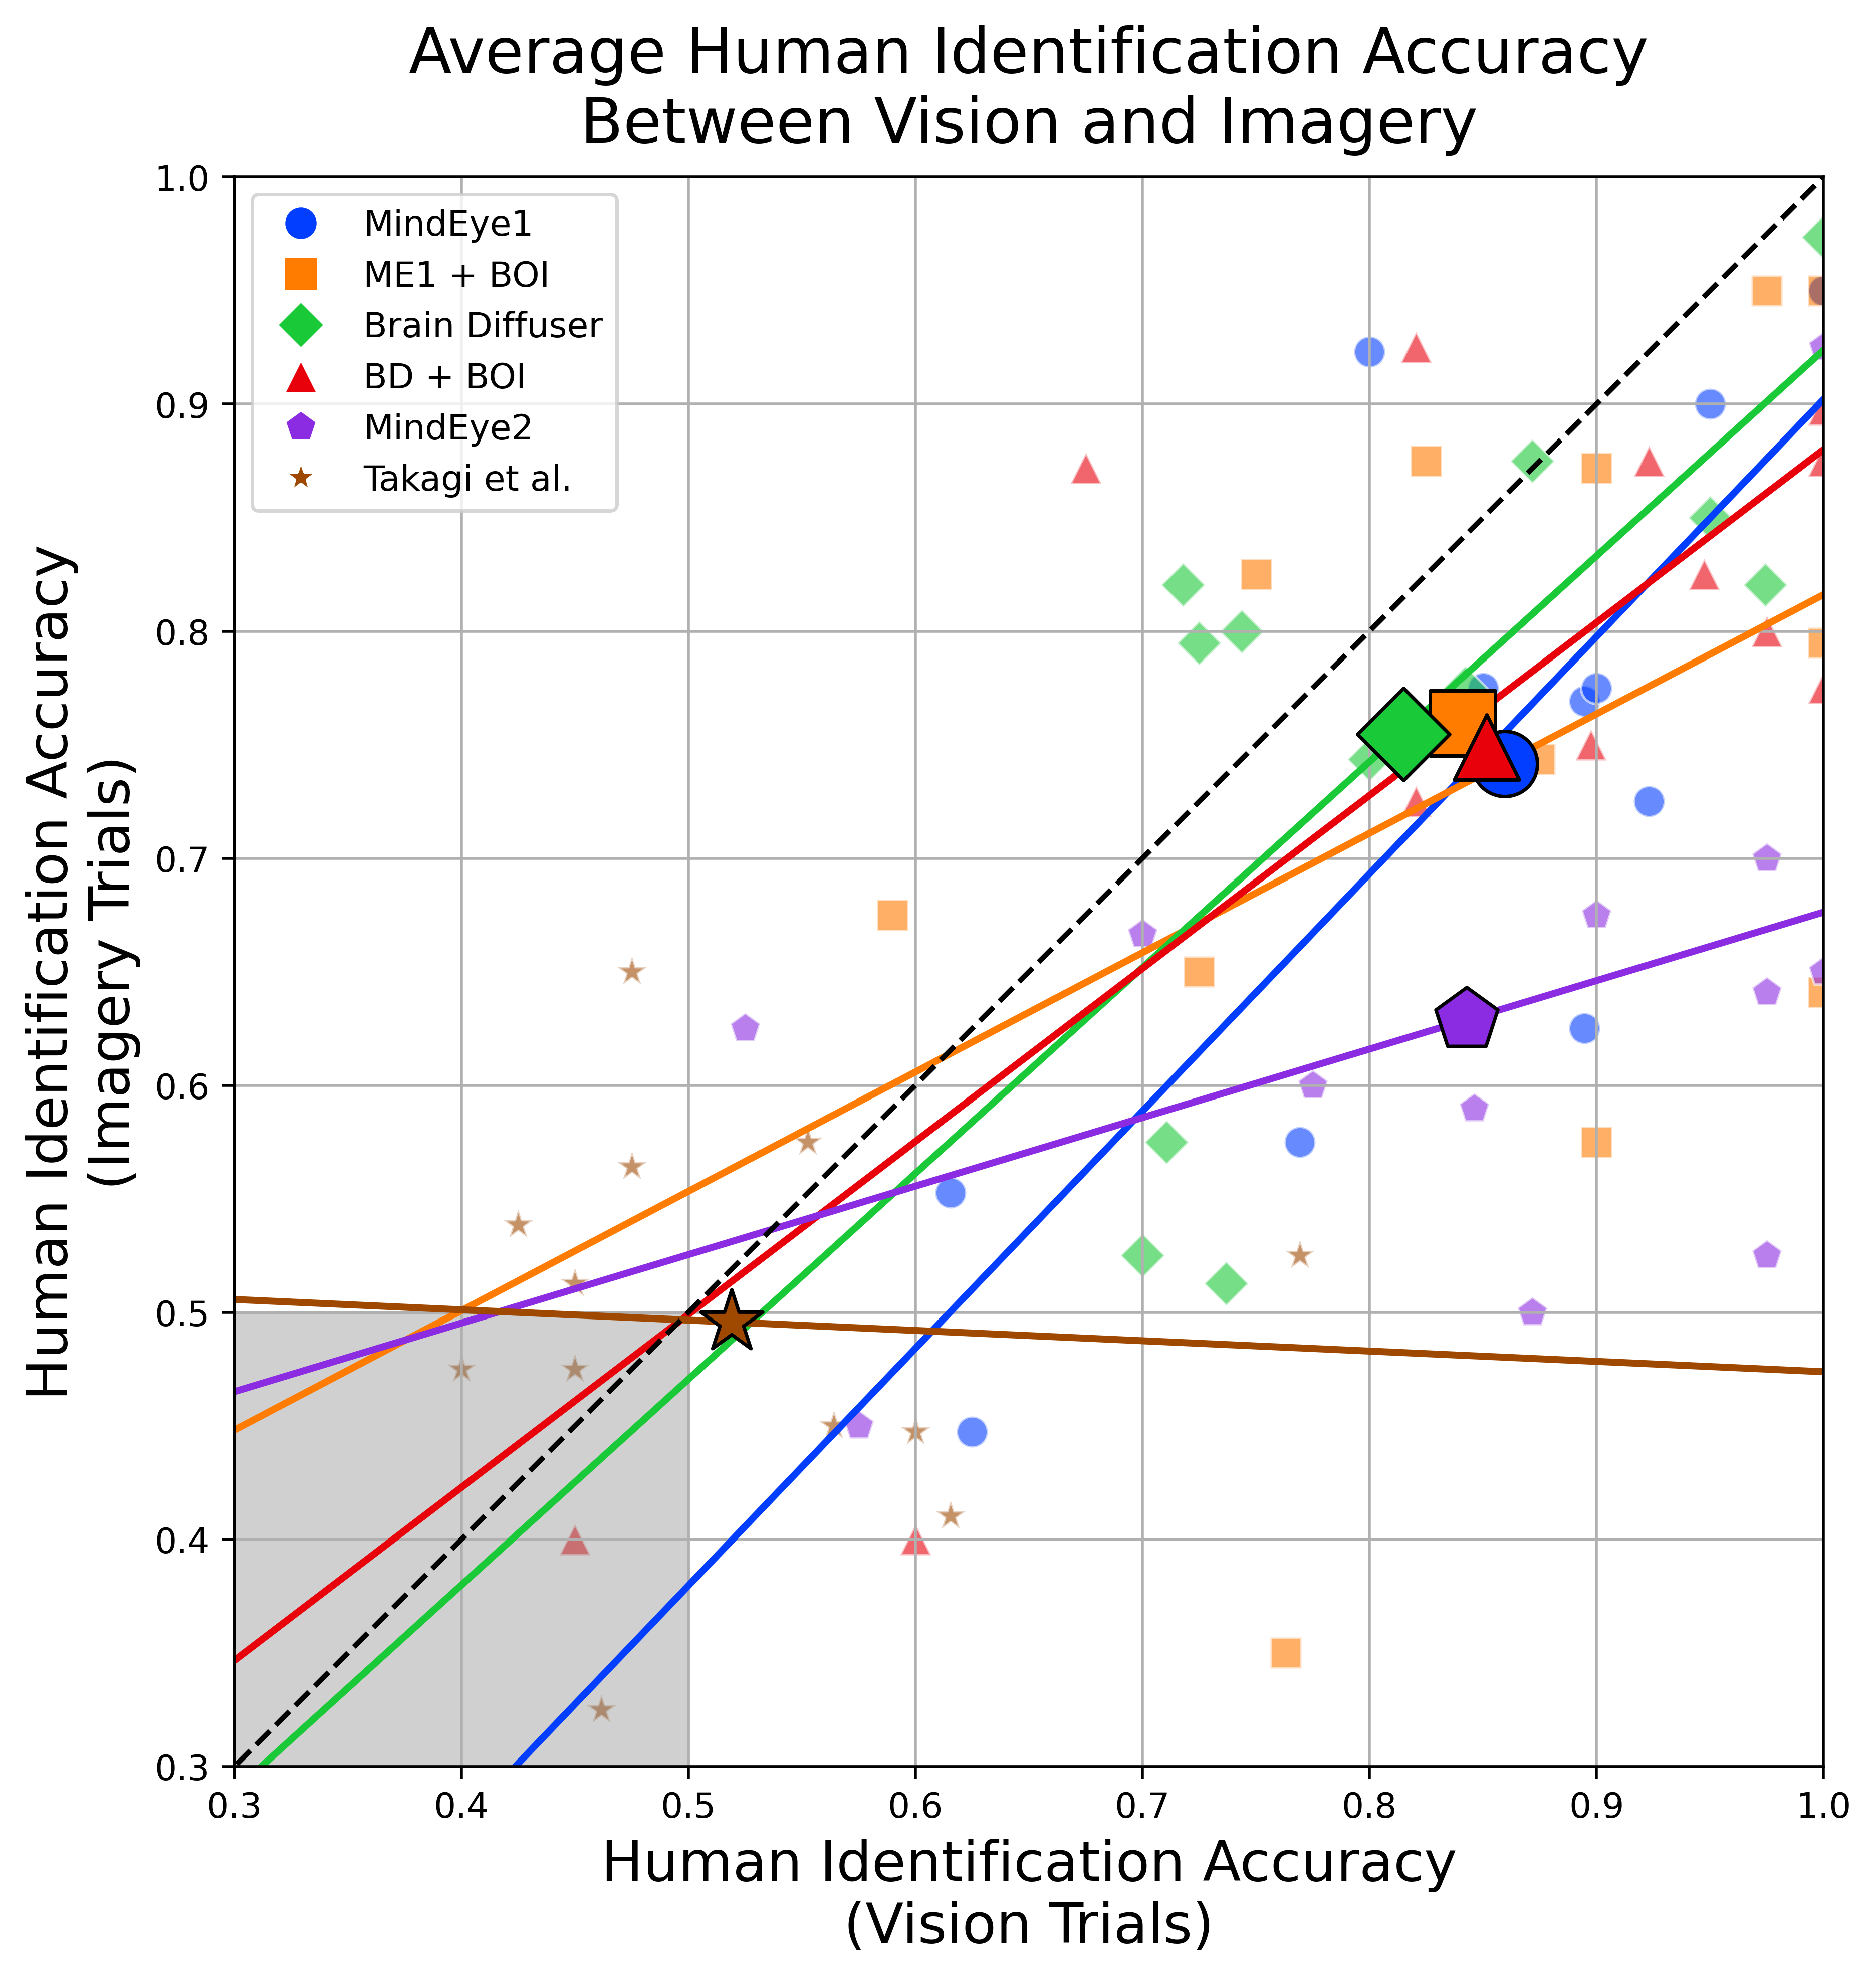

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

human_df = pd.read_csv(f'experiments/mi_evals_2_24/dataframes_v3/filtered_responses_v3.csv')
# human_df = pd.read_csv(f'experiments/dataframes/responses_v4_clean.csv')
human_df = human_df[(human_df['experiment'] == 1)]
print(human_df['method'].unique())
# Grouping and averaging
grouped_df = human_df.groupby(['method', 'mode', "sample"]).agg(correct_rate=('picked_target', 'mean')).reset_index() 

vision_data = grouped_df[grouped_df['mode'] == 'vision']
imagery_data = grouped_df[grouped_df['mode'] == 'imagery']
merged_data = pd.merge(
    vision_data, 
    imagery_data, 
    on=['method', 'sample'], 
    suffixes=('_vision', '_imagery')
)
print(merged_data['method'].unique())
# for row in merged_data.iterrows():
#     print(row)
# Define a clear mapping for method display names in the legend
method_display_names = {
    "mindeye": "MindEye1",
    "boi-v2.1": "ME1 + BOI",
    "braindiffuser": "Brain Diffuser",
    "boi-v2.3": "BD + BOI",
    "mindeye2": "MindEye2",
    "tagaki": "Takagi et al."
}


# Prepare the plot
fig, ax = plt.subplots(figsize=(8, 8), dpi=500)  # Create a square figure
bright_palette = sns.color_palette('bright', len(method_display_names))
markers = ['o', 's', 'D', '^', 'p', '*']

# First, plot the scatter and PCA lines for each method
for i, (method_code, method_display) in enumerate(method_display_names.items()):
    method_data = merged_data[merged_data['method'] == method_code]
    # Scatter plot for individual points
    sns.scatterplot(data=method_data, x='correct_rate_vision', y='correct_rate_imagery', color=bright_palette[i], 
                    label=method_display, s=80, marker=markers[i], alpha=0.6, ax=ax)

    # PCA for best fit line
    # Calculate the best fit line
    slope, intercept = np.polyfit(method_data['correct_rate_vision'], method_data['correct_rate_imagery'], 1)
    line_x = np.linspace(-0.1, 1.1, 100)
    line_y = slope * line_x + intercept
    ax.plot(line_x, line_y, color=bright_palette[i], linewidth=2)

# Then, plot the large dots for the mean of each method, ensuring they appear on top
for i, method_code in enumerate(merged_data['method'].unique()):
    method_data_vision = human_df[(human_df['method'] == method_code) & (human_df['mode'] == 'vision')]
    method_data_imagery = human_df[(human_df['method'] == method_code) & (human_df['mode'] == 'imagery')]
    avg_target_similarity = len(method_data_vision[method_data_vision["picked_target"]]) / len(method_data_vision)
    avg_distractor_similarity = len(method_data_imagery[method_data_imagery["picked_target"]]) / len(method_data_imagery)
    print(method_code, avg_target_similarity, avg_distractor_similarity)
    ax.scatter(avg_target_similarity, avg_distractor_similarity, color=bright_palette[i], marker=markers[i], s=350, edgecolors='black', zorder=5)

# Shading the region below 0.5 on both axes as the chance zone
ax.fill_betweenx([0, 0.5], 0, 0.5, color='gray', alpha=0.2)
ax.fill_between([0, 0.5], 0, 0.5, color='gray', alpha=0.2)

ax.set_title('Average Human Identification Accuracy\nBetween Vision and Imagery', pad=10, fontsize=18)
ax.set_xlabel('Human Identification Accuracy\n(Vision Trials)', fontsize=16)
ax.set_ylabel('Human Identification Accuracy\n(Imagery Trials)', fontsize=16)
plt.tight_layout()
ax.grid(True)
ax.set_xlim(0.3, 1)
ax.set_ylim(0.3, 1)
ax.set_aspect('equal', adjustable='box')
ax.plot([0, 1], [0, 1], 'k--')  # Line at unity

# Adjusting legend to make sure it represents the latest plotted elements correctly
handles, labels = ax.get_legend_handles_labels()
# Ensuring that new handles created for the legend represent the latest plot elements with the correct zorder
new_handles = [plt.Line2D([], [], marker=marker, color='w', markerfacecolor=bright_palette[i], markersize=10, alpha=1) for i, marker in enumerate(markers[:len(method_display_names)])]
ax.legend(new_handles, labels[:len(method_display_names)], bbox_to_anchor=(0, 1), loc='upper left', fontsize=10)

plt.show()
